In [1]:
import torch
import torchvision
from torch import nn, optim
from torch.nn import functional as F
import matplotlib.pyplot as plt
from pylab import rcParams
import numpy as np
import os
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# Set up plotting parameters
rcParams['figure.figsize'] = 8, 8
plt.ion()  # Interactive plotting

print("✅ All libraries imported successfully!")
print(f"PyTorch version: {torch.__version__}")
print(f"Using device: {'CUDA' if torch.cuda.is_available() else 'CPU'}")


✅ All libraries imported successfully!
PyTorch version: 2.15.0+cu132
Using device: CUDA


In [2]:
# Training configuration
BATCH_SIZE = 128        # How many data points to process at once
EPOCHS = 200           # How many times to see the entire dataset
LOG_INTERVAL = 50      # How often to print progress updates

# Model architecture
INPUT_DIM = 28 * 28
NOISE_DIM = 16
NUM_CLASSES = 10
GENERATOR_FEATURE_MAPS = 256
DISCRIMINATOR_FEATURE_MAPS = 256

# GAN-specific hyperparameters
LR_G = 4e-4           # Learning rate for Generator
LR_D = 2e-4           # Learning rate for Discriminator
BETA1 = 0.5           # Beta1 for Adam optimizer

# Visualization settings
SAVE_PLT_INTERVAL = 5   # How often to save plots (every 5 epochs)

# Set up device (use GPU if available, otherwise CPU)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

print(f"Batch size: {BATCH_SIZE}")
print(f"Epochs: {EPOCHS}")
print(f"Generator feature maps: {GENERATOR_FEATURE_MAPS}")
print(f"Discriminator feature maps: {DISCRIMINATOR_FEATURE_MAPS}")
print(f"Generator learning rate: {LR_G}")
print(f"Discriminator learning rate: {LR_D}")
print(f"Device: {device}")


Batch size: 128
Epochs: 200
Generator feature maps: 256
Discriminator feature maps: 256
Generator learning rate: 0.0004
Discriminator learning rate: 0.0002
Device: cuda


In [3]:
train_data = torchvision.datasets.FashionMNIST(
    root='data/',
    train=True,
    download=True,
    transform=torchvision.transforms.ToTensor()
)
test_data = torchvision.datasets.FashionMNIST(
    root='data/',
    train=False,
    download=True,
    transform=torchvision.transforms.ToTensor()
)

print(f"Training data shape: {train_data.data.shape}")
print(f"Test data shape: {test_data.data.shape}")

Training data shape: torch.Size([60000, 28, 28])
Test data shape: torch.Size([10000, 28, 28])


In [4]:
# Set up data loaders
# pin_memory=True speeds up data transfer to GPU (if available)
kwargs = {'num_workers': 4, 'pin_memory': True} if device.type == 'cuda' else {}

train_loader = torch.utils.data.DataLoader(
    train_data,
    batch_size=BATCH_SIZE,
    shuffle=True,
    **kwargs
)

test_loader = torch.utils.data.DataLoader(
    test_data,
    batch_size=BATCH_SIZE,
    shuffle=True,
    **kwargs
)

print(f"Batch size: {BATCH_SIZE}")
print(f"Training batches: {len(train_loader)}")
print(f"Test batches: {len(test_loader)}")

Batch size: 128
Training batches: 469
Test batches: 79


In [5]:
class Generator(nn.Module):
    def __init__(self, noise_dim, feature_maps, num_classes):
        super().__init__()
        self.num_classes = num_classes
        input_channels = noise_dim + num_classes

        self.net = nn.Sequential(
            nn.Unflatten(1, (input_channels, 1, 1)),

            nn.ConvTranspose2d(input_channels, feature_maps * 2, kernel_size=7, bias=False),
            nn.BatchNorm2d(feature_maps * 2),
            nn.ReLU(),

            nn.ConvTranspose2d(feature_maps * 2, feature_maps, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(feature_maps),
            nn.ReLU(),

            nn.ConvTranspose2d(feature_maps, 1, kernel_size=4, stride=2, padding=1),
            nn.Sigmoid(),
        )

    def forward(self, noise, labels):
        class_vectors = F.one_hot(labels, num_classes=self.num_classes).to(noise.dtype)
        return self.net(torch.cat((noise, class_vectors), dim=1))


In [6]:
class Discriminator(nn.Module):
    def __init__(self, feature_maps, num_classes):
        super().__init__()
        self.num_classes = num_classes

        self.net = nn.Sequential(
            nn.Conv2d(1 + num_classes, feature_maps, kernel_size=4, stride=2, padding=1),
            nn.LeakyReLU(0.2),

            nn.Conv2d(feature_maps, feature_maps * 2, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(feature_maps * 2),
            nn.LeakyReLU(0.2),

            nn.Conv2d(feature_maps * 2, 1, kernel_size=3, stride=1, padding=1),
            nn.Sigmoid(),
        )

    def forward(self, data, labels):
        class_maps = F.one_hot(labels, num_classes=self.num_classes).to(data.dtype)
        class_maps = class_maps[:, :, None, None].expand(-1, -1, data.size(2), data.size(3))
        return self.net(torch.cat((data, class_maps), dim=1))


In [7]:
# Initialize models
generator = Generator(NOISE_DIM, GENERATOR_FEATURE_MAPS, NUM_CLASSES)
discriminator = Discriminator(DISCRIMINATOR_FEATURE_MAPS, NUM_CLASSES)

# Move models to device and ensure correct dtype
generator = generator.to(device).float()
discriminator = discriminator.to(device).float()

# Set up optimizers for both networks
# We use different optimizers for Generator and Discriminator
optimizer_G = torch.optim.Adam(generator.parameters(), lr=LR_G, betas=(BETA1, 0.999))
optimizer_D = torch.optim.Adam(discriminator.parameters(), lr=LR_D, betas=(BETA1, 0.999))

# Loss function for GAN training
criterion = nn.BCELoss()  # Binary Cross Entropy Loss

print(f"Generator parameters: {sum(p.numel() for p in generator.parameters()):,}")
print(f"Discriminator parameters: {sum(p.numel() for p in discriminator.parameters()):,}")
print(f"Generator learning rate: {LR_G}")
print(f"Discriminator learning rate: {LR_D}")
print(f"Models moved to device: {device}")
print(f"Models dtype: {next(generator.parameters()).dtype}")

# Let's see what our models look like
print("\nGenerator architecture:")
print(generator)
print("\nDiscriminator architecture:")
print(discriminator)


Generator parameters: 2,755,073
Discriminator parameters: 2,148,097
Generator learning rate: 0.0004
Discriminator learning rate: 0.0002
Models moved to device: cuda
Models dtype: torch.float32

Generator architecture:
Generator(
  (net): Sequential(
    (0): Unflatten(dim=1, unflattened_size=(26, 1, 1))
    (1): ConvTranspose2d(26, 512, kernel_size=(7, 7), stride=(1, 1), bias=False)
    (2): BatchNorm2d(512, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (3): ReLU()
    (4): ConvTranspose2d(512, 256, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (5): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): ConvTranspose2d(256, 1, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (8): Sigmoid()
  )
)

Discriminator architecture:
Discriminator(
  (net): Sequential(
    (0): Conv2d(11, 256, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (1): LeakyReLU(negative_slop

In [8]:
def visualize_class_samples(classes, samples_per_class=5):
    class_labels = np.repeat(classes, samples_per_class)
    samples = generate_samples(len(class_labels), classes=class_labels)
    fig, axes = plt.subplots(
        len(classes), samples_per_class,
        figsize=(samples_per_class * 2, len(classes) * 2), squeeze=False,
    )

    for row, class_label in enumerate(classes):
        for column in range(samples_per_class):
            sample_index = row * samples_per_class + column
            axes[row, column].imshow(samples[sample_index].reshape(28, 28), cmap='gray', vmin=0, vmax=1)
            axes[row, column].set_title(f'Class {class_label}')
            axes[row, column].axis('off')

    fig.tight_layout()
    plt.show()


In [9]:
def train_discriminator(real_data, class_labels):
    optimizer_D.zero_grad()
    real_data = real_data.to(device).float()
    class_labels = class_labels.to(device=device, dtype=torch.long)
    batch_size = real_data.size(0)

    real_output = discriminator(real_data, class_labels)
    real_targets = torch.ones_like(real_output)
    real_loss = criterion(real_output, real_targets)

    noise = torch.randn(batch_size, NOISE_DIM, device=device)
    with torch.no_grad():
        fake_data = generator(noise, class_labels)
    fake_output = discriminator(fake_data, class_labels)
    fake_targets = torch.zeros_like(fake_output)
    fake_loss = criterion(fake_output, fake_targets)

    d_loss = real_loss + fake_loss
    d_loss.backward()
    optimizer_D.step()
    return d_loss.item()


def evaluate_discriminator(real_data, class_labels):
    with torch.no_grad():
        real_data = real_data.to(device).float()
        class_labels = class_labels.to(device=device, dtype=torch.long)
        batch_size = real_data.size(0)

        real_output = discriminator(real_data, class_labels)
        real_targets = torch.ones_like(real_output)
        real_loss = criterion(real_output, real_targets)

        noise = torch.randn(batch_size, NOISE_DIM, device=device)
        fake_data = generator(noise, class_labels)
        fake_output = discriminator(fake_data, class_labels)
        fake_targets = torch.zeros_like(fake_output)
        fake_loss = criterion(fake_output, fake_targets)
        d_loss = real_loss + fake_loss

    return d_loss.item()


In [10]:
def train_generator(class_labels):
    optimizer_G.zero_grad()
    class_labels = class_labels.to(device=device, dtype=torch.long)
    batch_size = class_labels.size(0)

    noise = torch.randn(batch_size, NOISE_DIM, device=device)
    fake_data = generator(noise, class_labels)
    fake_output = discriminator(fake_data, class_labels)
    real_targets = torch.ones_like(fake_output)
    g_loss = criterion(fake_output, real_targets)

    g_loss.backward()
    optimizer_G.step()
    return g_loss.item()


def evaluate_generator(class_labels):
    with torch.no_grad():
        class_labels = class_labels.to(device=device, dtype=torch.long)
        batch_size = class_labels.size(0)

        noise = torch.randn(batch_size, NOISE_DIM, device=device)
        fake_data = generator(noise, class_labels)
        fake_output = discriminator(fake_data, class_labels)
        real_targets = torch.ones_like(fake_output)
        g_loss = criterion(fake_output, real_targets)

    return g_loss.item()


In [11]:
def train_epoch_with_validation(epoch):
    """
    Train both Generator and Discriminator for one epoch with validation.
    
    Args:
        epoch: Current epoch number
    
    Returns:
        avg_d_loss: Average discriminator training loss for this epoch
        avg_g_loss: Average generator training loss for this epoch
        val_d_loss: Average discriminator validation loss
        val_g_loss: Average generator validation loss
    """
    # Set models to training mode
    generator.train()
    discriminator.train()
    
    # Track losses
    d_losses = []
    g_losses = []
    
    for batch_idx, (data, labels) in enumerate(train_loader):
        data = data.to(device)
        
        # Train Discriminator
        d_loss = train_discriminator(data, labels)
        d_losses.append(d_loss)

        # Train Generator
        g_loss = train_generator(labels)
        g_losses.append(g_loss)
        
        # Print progress
        if batch_idx % LOG_INTERVAL == 0:
            print('Epoch: {} [{}/{} ({:.0f}%)]\tD_loss: {:.6f}\tG_loss: {:.6f}'.format(
                epoch, batch_idx * len(data), len(train_loader.dataset),
                100. * batch_idx / len(train_loader), d_loss, g_loss))
    
    # Calculate average training losses
    avg_d_loss = sum(d_losses) / len(d_losses)
    avg_g_loss = sum(g_losses) / len(g_losses)
    
    # Evaluate on validation set
    generator.eval()
    discriminator.eval()
    
    val_d_losses = []
    val_g_losses = []
    
    for batch_idx, (data, labels) in enumerate(test_loader):
        
        # Evaluate Discriminator
        val_d_loss = evaluate_discriminator(data, labels)
        val_d_losses.append(val_d_loss)
        
        # Evaluate Generator
        val_g_loss = evaluate_generator(labels)
        val_g_losses.append(val_g_loss)
    
    # Calculate average validation losses
    val_d_loss = sum(val_d_losses) / len(val_d_losses)
    val_g_loss = sum(val_g_losses) / len(val_g_losses)
    
    print('====> Epoch: {} Train D_loss: {:.4f}, Train G_loss: {:.4f}'.format(
        epoch, avg_d_loss, avg_g_loss))
    print('====> Epoch: {} Val D_loss: {:.4f}, Val G_loss: {:.4f}'.format(
        epoch, val_d_loss, val_g_loss))
    
    return avg_d_loss, avg_g_loss, val_d_loss, val_g_loss


In [12]:
def generate_samples(num_samples=1000, classes=None):
    if isinstance(num_samples, bool) or not isinstance(num_samples, (int, np.integer)) or num_samples <= 0:
        raise ValueError('num_samples must be a positive integer')

    if classes is None:
        class_labels = torch.randint(NUM_CLASSES, (num_samples,), device=device)
    else:
        class_labels = torch.as_tensor(classes, device=device)
        if class_labels.dtype == torch.bool or class_labels.is_floating_point() or class_labels.is_complex():
            raise ValueError('classes must contain integer class labels')
        if class_labels.ndim == 0:
            class_labels = class_labels.repeat(num_samples)
        if class_labels.ndim != 1 or class_labels.numel() != num_samples:
            raise ValueError('Provide one class or one class per generated sample')
        if torch.any((class_labels < 0) | (class_labels >= NUM_CLASSES)):
            raise ValueError(f'classes must be between 0 and {NUM_CLASSES - 1}')
        class_labels = class_labels.long()

    was_training = generator.training
    generator.eval()
    try:
        with torch.no_grad():
            samples = []
            for start in range(0, num_samples, BATCH_SIZE):
                batch_labels = class_labels[start:start + BATCH_SIZE]
                noise = torch.randn(len(batch_labels), NOISE_DIM, device=device)
                samples.append(generator(noise, batch_labels).flatten(1).cpu())
            return torch.cat(samples).numpy()
    finally:
        generator.train(was_training)


def pca_fit(data):
    pipeline = Pipeline([
        ('scaling', StandardScaler()),
        ('pca', PCA(n_components=2))
    ])
    pipeline.fit(data)

    return pipeline


In [13]:
# Simplified visualization function without validation
def visualize_training_progress(epoch, train_d_losses, train_g_losses, val_d_losses, val_g_losses):
    """
    Visualize the current state of our GAN training with loss plots.
    
    Args:
        epoch: Current epoch number
        train_d_losses: List of discriminator training losses
        train_g_losses: List of generator training losses
        save_plot: Whether to save the plot to disk
    """
    # Generate samples
    generated_classes = np.arange(2000) % NUM_CLASSES
    generated_samples = generate_samples(2000, classes=generated_classes)
    
    # Create visualization with 2x3 subplots
    plt.figure(figsize=(18, 10))

    train_data_reshaped = np.reshape(train_data.data[:2000], [2000, INPUT_DIM])
    data_transformed = pca_fit(train_data_reshaped).transform(train_data_reshaped)
    x_transformed = pca_fit(generated_samples).transform(generated_samples)

    # Original training data
    plt.subplot(2, 3, 1)
    plt.scatter(data_transformed[:, 0], data_transformed[:, 1], c='blue', s=1, alpha=0.6)
    plt.title('Original Training Data')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.grid(True, alpha=0.3)

    # Generated samples
    plt.subplot(2, 3, 2)
    plt.scatter(x_transformed[:, 0], x_transformed[:, 1], c='red', s=1, alpha=0.6)
    plt.title('Generated Samples')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.grid(True, alpha=0.3)

    # Overlay comparison
    plt.subplot(2, 3, 3)
    plt.scatter(data_transformed[:, 0], data_transformed[:, 1], c='blue', s=1, alpha=0.3, label='Original')
    plt.scatter(x_transformed[:, 0], x_transformed[:, 1], c='red', s=1, alpha=0.3, label='Generated')
    plt.title('Overlay Comparison')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.legend()
    plt.grid(True, alpha=0.3)
    
    # Skip first 5 epochs for loss plotting (due to big magnitude)
    skip_epochs = 5
    if len(train_d_losses) > skip_epochs:
        # Discriminator losses (skip first 5 epochs)
        plt.subplot(2, 3, 4)
        epochs_range = range(skip_epochs + 1, len(train_d_losses) + 1)
        plt.plot(epochs_range, train_d_losses[skip_epochs:], 'b-', label='Train D Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Discriminator Loss')
        plt.title(f'Discriminator Training Progress\n(Skipping first {skip_epochs} epochs)')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        # Generator losses (skip first 5 epochs)
        plt.subplot(2, 3, 5)
        plt.plot(epochs_range, train_g_losses[skip_epochs:], 'r-', label='Train G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Generator Loss')
        plt.title(f'Generator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        # Combined loss plot (skip first 5 epochs)
        plt.subplot(2, 3, 6)
        plt.plot(epochs_range, train_d_losses[skip_epochs:], 'b-', label='Train D Loss', linewidth=2)
        plt.plot(epochs_range, train_g_losses[skip_epochs:], 'r-', label='Train G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.title(f'Combined Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
    else:
        # If we don't have enough epochs yet, show all
        plt.subplot(2, 3, 4)
        epochs_range = range(1, len(train_d_losses) + 1)
        plt.plot(epochs_range, train_d_losses, 'b-', label='Train D Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Discriminator Loss')
        plt.title('Discriminator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        plt.subplot(2, 3, 5)
        plt.plot(epochs_range, train_g_losses, 'r-', label='Train G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Generator Loss')
        plt.title('Generator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        plt.subplot(2, 3, 6)
        plt.plot(epochs_range, train_d_losses, 'b-', label='Train D Loss', linewidth=2)
        plt.plot(epochs_range, train_g_losses, 'r-', label='Train G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.title('Combined Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
    
    plt.tight_layout()
    
    plt.show()

    visualize_class_samples(list(range(NUM_CLASSES)), samples_per_class=2)


🎯 Starting GAN training...
📊 Initial state (before training):

📊 Epoch 1/200
----------------------------------------
Epoch: 1 [0/60000 (0%)]	D_loss: 1.430865	G_loss: 0.825631
Epoch: 1 [6400/60000 (11%)]	D_loss: 1.205562	G_loss: 0.900646
Epoch: 1 [12800/60000 (21%)]	D_loss: 1.127235	G_loss: 1.098470
Epoch: 1 [19200/60000 (32%)]	D_loss: 1.227673	G_loss: 0.817289
Epoch: 1 [25600/60000 (43%)]	D_loss: 1.342524	G_loss: 0.751498
Epoch: 1 [32000/60000 (53%)]	D_loss: 1.393181	G_loss: 0.707816
Epoch: 1 [38400/60000 (64%)]	D_loss: 1.375586	G_loss: 0.715478
Epoch: 1 [44800/60000 (75%)]	D_loss: 1.398896	G_loss: 0.707944
Epoch: 1 [51200/60000 (85%)]	D_loss: 1.383226	G_loss: 0.712638
Epoch: 1 [57600/60000 (96%)]	D_loss: 1.378631	G_loss: 0.708891
====> Epoch: 1 Train D_loss: 1.3123, Train G_loss: 0.7995
====> Epoch: 1 Val D_loss: 1.3912, Val G_loss: 0.6997
📈 Epoch 1 Summary:
   Train D Loss: 1.3123, Val D Loss: 1.3912
   Train G Loss: 0.7995, Val G Loss: 0.6997

📊 Epoch 2/200
------------------------

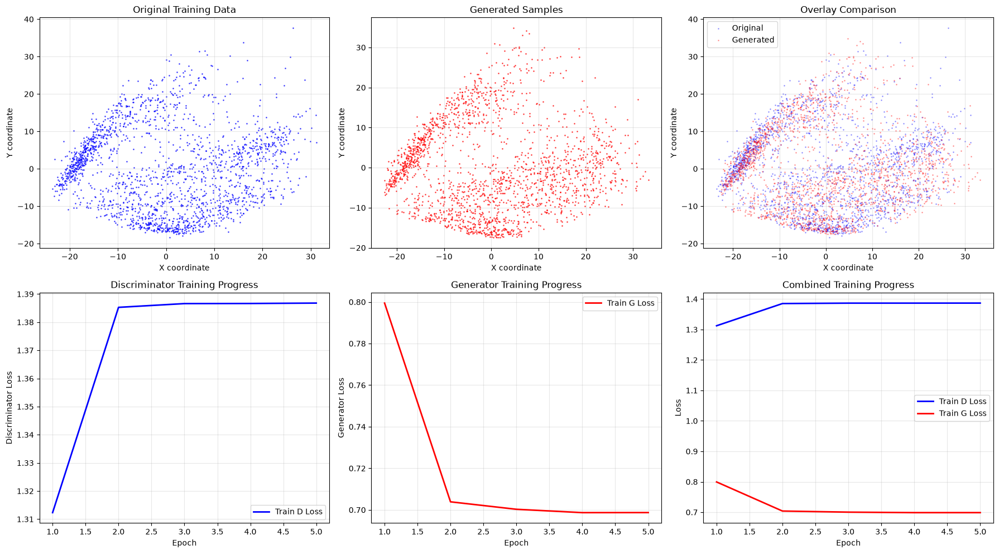

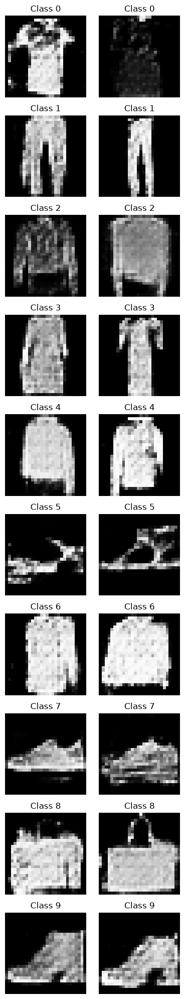

📈 Epoch 5 Summary:
   Train D Loss: 1.3868, Val D Loss: 1.3860
   Train G Loss: 0.6987, Val G Loss: 0.7657

📊 Epoch 6/200
----------------------------------------
Epoch: 6 [0/60000 (0%)]	D_loss: 1.383591	G_loss: 0.690996
Epoch: 6 [6400/60000 (11%)]	D_loss: 1.386175	G_loss: 0.693162
Epoch: 6 [12800/60000 (21%)]	D_loss: 1.390229	G_loss: 0.696241
Epoch: 6 [19200/60000 (32%)]	D_loss: 1.388330	G_loss: 0.697682
Epoch: 6 [25600/60000 (43%)]	D_loss: 1.388238	G_loss: 0.699253
Epoch: 6 [32000/60000 (53%)]	D_loss: 1.385002	G_loss: 0.714426
Epoch: 6 [38400/60000 (64%)]	D_loss: 1.388136	G_loss: 0.710964
Epoch: 6 [44800/60000 (75%)]	D_loss: 1.386930	G_loss: 0.688451
Epoch: 6 [51200/60000 (85%)]	D_loss: 1.389706	G_loss: 0.705827
Epoch: 6 [57600/60000 (96%)]	D_loss: 1.386891	G_loss: 0.709767
====> Epoch: 6 Train D_loss: 1.3864, Train G_loss: 0.6983
====> Epoch: 6 Val D_loss: 1.3816, Val G_loss: 0.7135
📈 Epoch 6 Summary:
   Train D Loss: 1.3864, Val D Loss: 1.3816
   Train G Loss: 0.6983, Val G Loss: 0

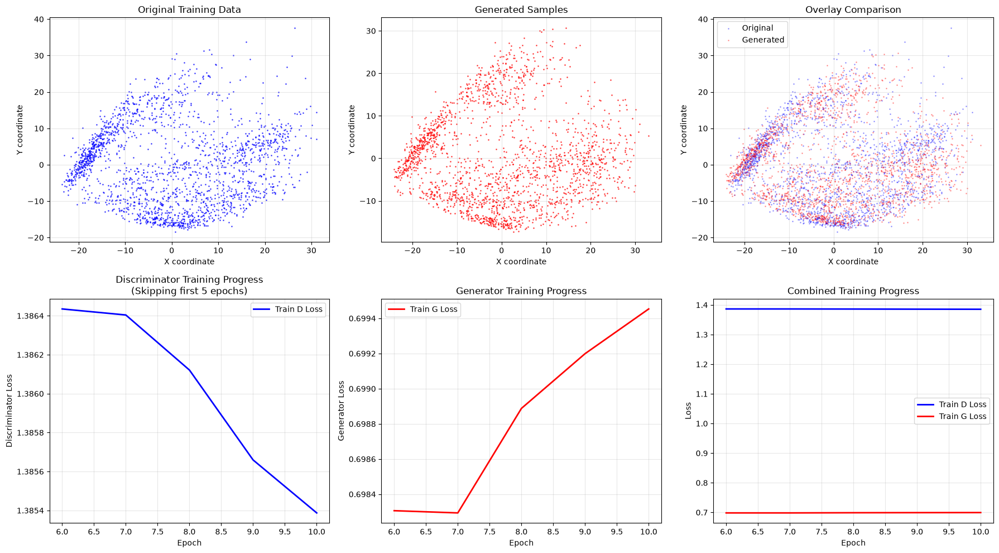

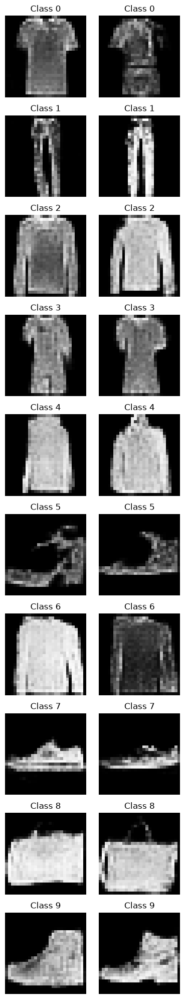

📈 Epoch 10 Summary:
   Train D Loss: 1.3854, Val D Loss: 1.3796
   Train G Loss: 0.6995, Val G Loss: 0.6880

📊 Epoch 11/200
----------------------------------------
Epoch: 11 [0/60000 (0%)]	D_loss: 1.391881	G_loss: 0.693001
Epoch: 11 [6400/60000 (11%)]	D_loss: 1.395416	G_loss: 0.703449
Epoch: 11 [12800/60000 (21%)]	D_loss: 1.383847	G_loss: 0.705998
Epoch: 11 [19200/60000 (32%)]	D_loss: 1.387596	G_loss: 0.700036
Epoch: 11 [25600/60000 (43%)]	D_loss: 1.384815	G_loss: 0.702534
Epoch: 11 [32000/60000 (53%)]	D_loss: 1.386497	G_loss: 0.702138
Epoch: 11 [38400/60000 (64%)]	D_loss: 1.385795	G_loss: 0.690029
Epoch: 11 [44800/60000 (75%)]	D_loss: 1.379534	G_loss: 0.693698
Epoch: 11 [51200/60000 (85%)]	D_loss: 1.386127	G_loss: 0.711300
Epoch: 11 [57600/60000 (96%)]	D_loss: 1.382088	G_loss: 0.685377
====> Epoch: 11 Train D_loss: 1.3848, Train G_loss: 0.7008
====> Epoch: 11 Val D_loss: 1.3876, Val G_loss: 0.6800
📈 Epoch 11 Summary:
   Train D Loss: 1.3848, Val D Loss: 1.3876
   Train G Loss: 0.7008

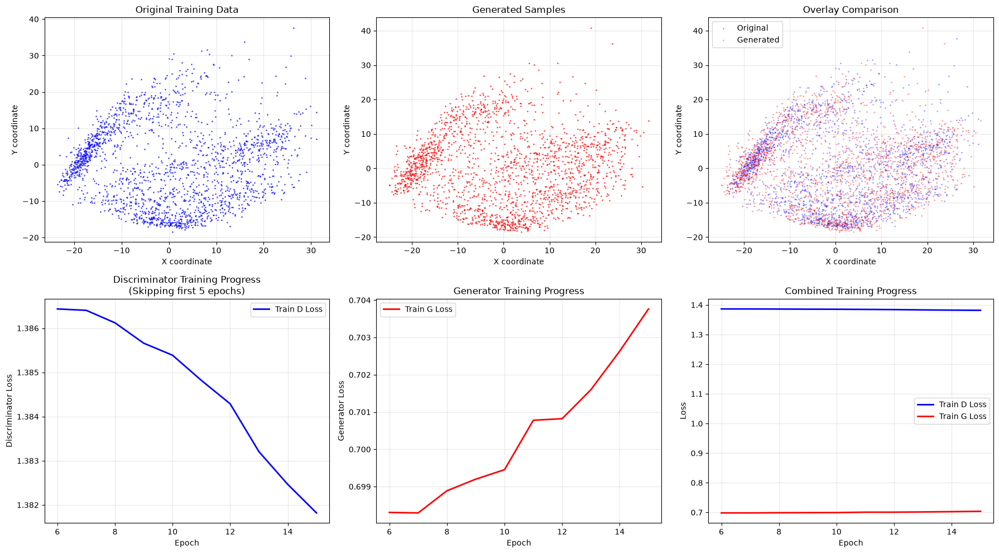

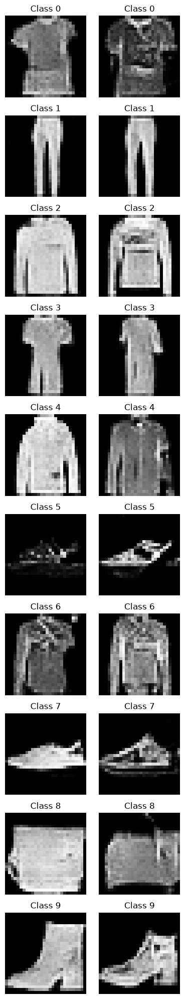

📈 Epoch 15 Summary:
   Train D Loss: 1.3818, Val D Loss: 1.3792
   Train G Loss: 0.7038, Val G Loss: 0.7006

📊 Epoch 16/200
----------------------------------------
Epoch: 16 [0/60000 (0%)]	D_loss: 1.378995	G_loss: 0.706638
Epoch: 16 [6400/60000 (11%)]	D_loss: 1.383116	G_loss: 0.701549
Epoch: 16 [12800/60000 (21%)]	D_loss: 1.380080	G_loss: 0.695720
Epoch: 16 [19200/60000 (32%)]	D_loss: 1.385069	G_loss: 0.711506
Epoch: 16 [25600/60000 (43%)]	D_loss: 1.377116	G_loss: 0.711238
Epoch: 16 [32000/60000 (53%)]	D_loss: 1.385767	G_loss: 0.691379
Epoch: 16 [38400/60000 (64%)]	D_loss: 1.379041	G_loss: 0.699354
Epoch: 16 [44800/60000 (75%)]	D_loss: 1.380292	G_loss: 0.709084
Epoch: 16 [51200/60000 (85%)]	D_loss: 1.380998	G_loss: 0.695448
Epoch: 16 [57600/60000 (96%)]	D_loss: 1.381986	G_loss: 0.702152
====> Epoch: 16 Train D_loss: 1.3807, Train G_loss: 0.7040
====> Epoch: 16 Val D_loss: 1.3813, Val G_loss: 0.7191
📈 Epoch 16 Summary:
   Train D Loss: 1.3807, Val D Loss: 1.3813
   Train G Loss: 0.7040

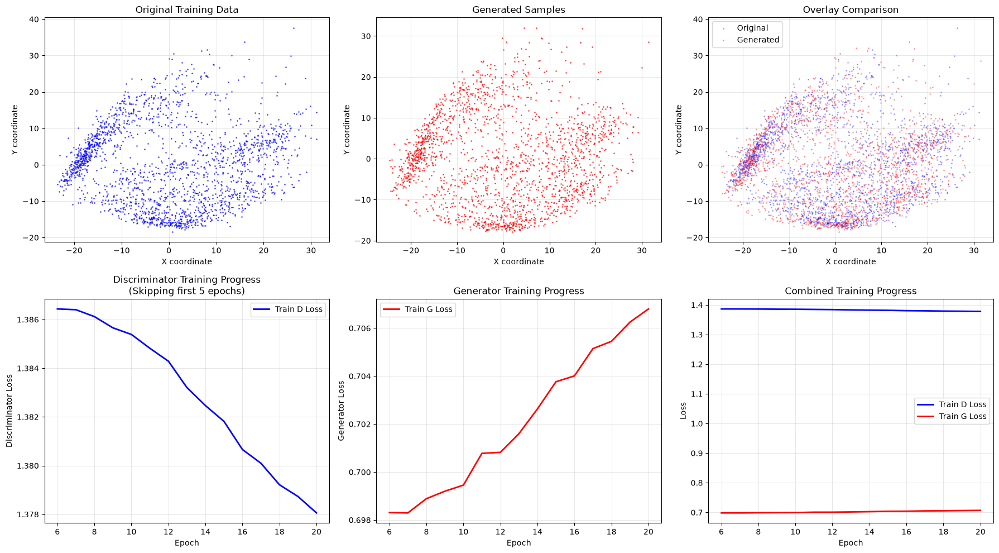

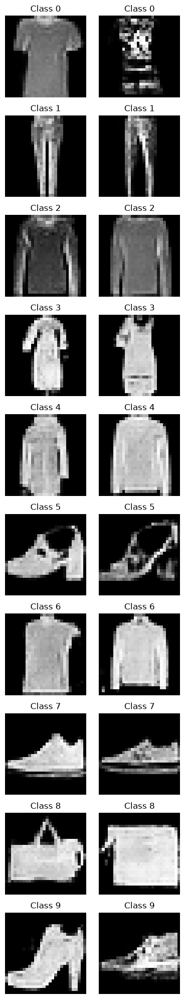

📈 Epoch 20 Summary:
   Train D Loss: 1.3781, Val D Loss: 1.3789
   Train G Loss: 0.7068, Val G Loss: 0.6854

📊 Epoch 21/200
----------------------------------------
Epoch: 21 [0/60000 (0%)]	D_loss: 1.375874	G_loss: 0.709245
Epoch: 21 [6400/60000 (11%)]	D_loss: 1.382682	G_loss: 0.699651
Epoch: 21 [12800/60000 (21%)]	D_loss: 1.378083	G_loss: 0.704067
Epoch: 21 [19200/60000 (32%)]	D_loss: 1.372726	G_loss: 0.711637
Epoch: 21 [25600/60000 (43%)]	D_loss: 1.372366	G_loss: 0.703652
Epoch: 21 [32000/60000 (53%)]	D_loss: 1.374495	G_loss: 0.713278
Epoch: 21 [38400/60000 (64%)]	D_loss: 1.372617	G_loss: 0.715969
Epoch: 21 [44800/60000 (75%)]	D_loss: 1.375598	G_loss: 0.711780
Epoch: 21 [51200/60000 (85%)]	D_loss: 1.384646	G_loss: 0.702335
Epoch: 21 [57600/60000 (96%)]	D_loss: 1.377737	G_loss: 0.704684
====> Epoch: 21 Train D_loss: 1.3774, Train G_loss: 0.7080
====> Epoch: 21 Val D_loss: 1.3873, Val G_loss: 0.6999
📈 Epoch 21 Summary:
   Train D Loss: 1.3774, Val D Loss: 1.3873
   Train G Loss: 0.7080

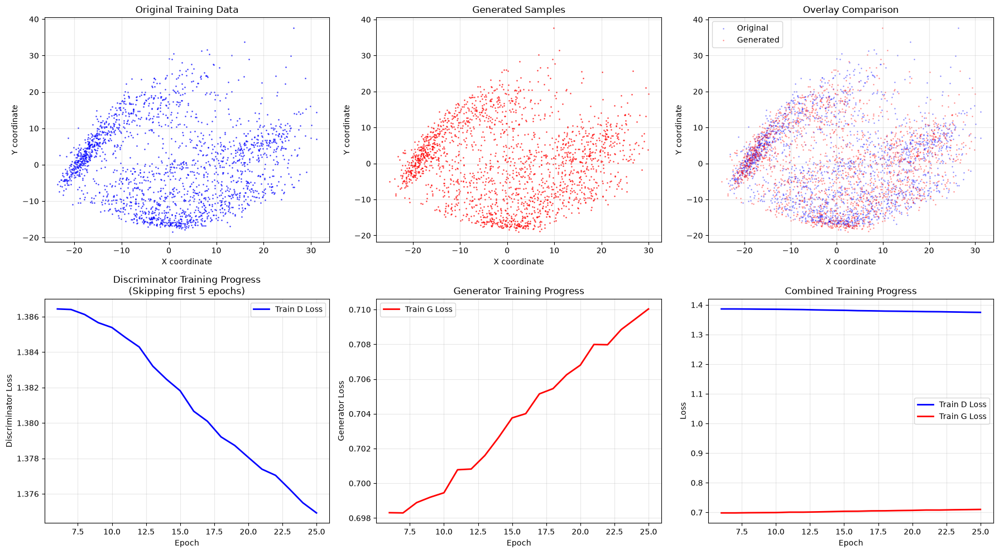

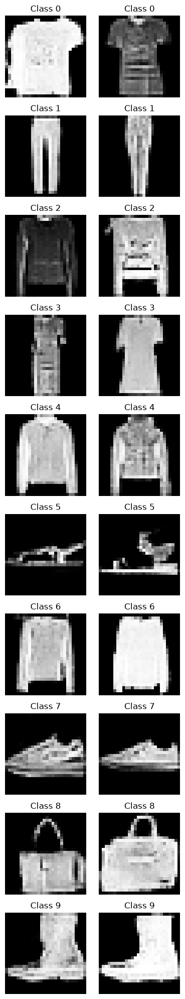

📈 Epoch 25 Summary:
   Train D Loss: 1.3749, Val D Loss: 1.3823
   Train G Loss: 0.7100, Val G Loss: 0.7201

📊 Epoch 26/200
----------------------------------------
Epoch: 26 [0/60000 (0%)]	D_loss: 1.370409	G_loss: 0.710866
Epoch: 26 [6400/60000 (11%)]	D_loss: 1.390903	G_loss: 0.706787
Epoch: 26 [12800/60000 (21%)]	D_loss: 1.375520	G_loss: 0.710622
Epoch: 26 [19200/60000 (32%)]	D_loss: 1.370867	G_loss: 0.703287
Epoch: 26 [25600/60000 (43%)]	D_loss: 1.375386	G_loss: 0.721038
Epoch: 26 [32000/60000 (53%)]	D_loss: 1.381804	G_loss: 0.703869
Epoch: 26 [38400/60000 (64%)]	D_loss: 1.385103	G_loss: 0.700649
Epoch: 26 [44800/60000 (75%)]	D_loss: 1.367117	G_loss: 0.721256
Epoch: 26 [51200/60000 (85%)]	D_loss: 1.366978	G_loss: 0.708280
Epoch: 26 [57600/60000 (96%)]	D_loss: 1.367407	G_loss: 0.694793
====> Epoch: 26 Train D_loss: 1.3744, Train G_loss: 0.7113
====> Epoch: 26 Val D_loss: 1.3732, Val G_loss: 0.6980
📈 Epoch 26 Summary:
   Train D Loss: 1.3744, Val D Loss: 1.3732
   Train G Loss: 0.7113

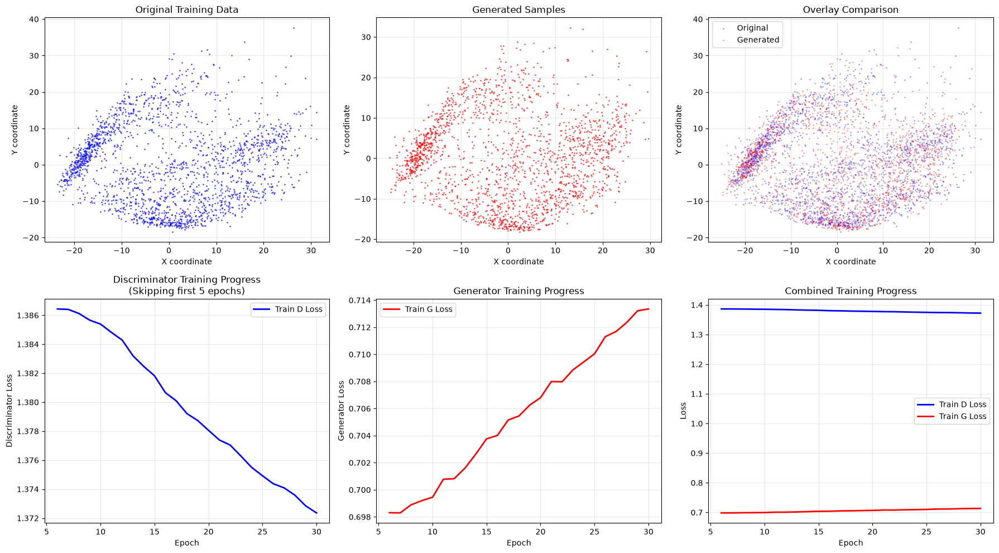

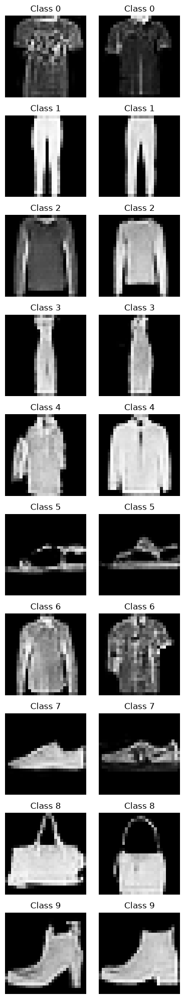

📈 Epoch 30 Summary:
   Train D Loss: 1.3724, Val D Loss: 1.3798
   Train G Loss: 0.7134, Val G Loss: 0.6760

📊 Epoch 31/200
----------------------------------------
Epoch: 31 [0/60000 (0%)]	D_loss: 1.363262	G_loss: 0.723472
Epoch: 31 [6400/60000 (11%)]	D_loss: 1.368622	G_loss: 0.723424
Epoch: 31 [12800/60000 (21%)]	D_loss: 1.365423	G_loss: 0.714480
Epoch: 31 [19200/60000 (32%)]	D_loss: 1.368474	G_loss: 0.718263
Epoch: 31 [25600/60000 (43%)]	D_loss: 1.364531	G_loss: 0.707820
Epoch: 31 [32000/60000 (53%)]	D_loss: 1.374574	G_loss: 0.708478
Epoch: 31 [38400/60000 (64%)]	D_loss: 1.378210	G_loss: 0.709137
Epoch: 31 [44800/60000 (75%)]	D_loss: 1.370521	G_loss: 0.698757
Epoch: 31 [51200/60000 (85%)]	D_loss: 1.365744	G_loss: 0.709771
Epoch: 31 [57600/60000 (96%)]	D_loss: 1.370363	G_loss: 0.715028
====> Epoch: 31 Train D_loss: 1.3719, Train G_loss: 0.7140
====> Epoch: 31 Val D_loss: 1.3818, Val G_loss: 0.7246
📈 Epoch 31 Summary:
   Train D Loss: 1.3719, Val D Loss: 1.3818
   Train G Loss: 0.7140

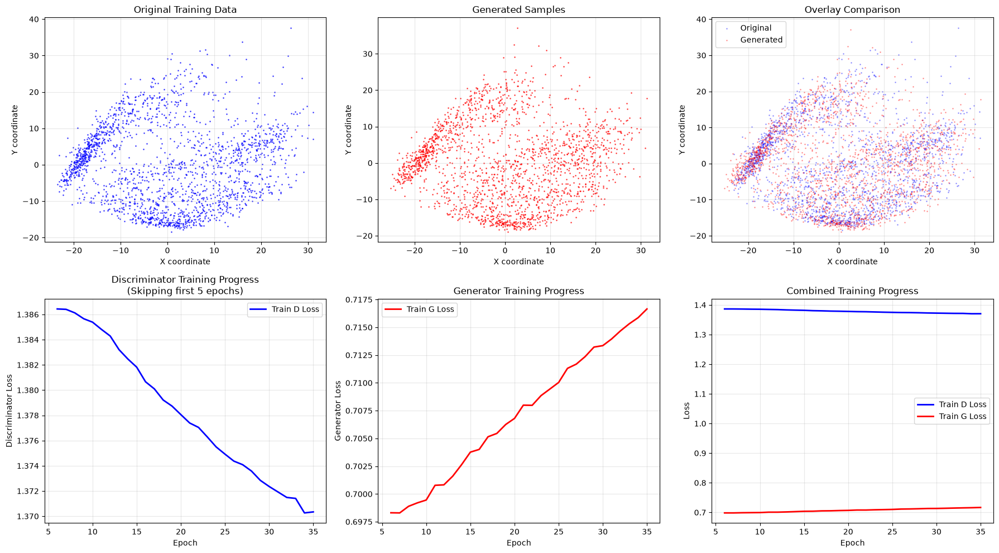

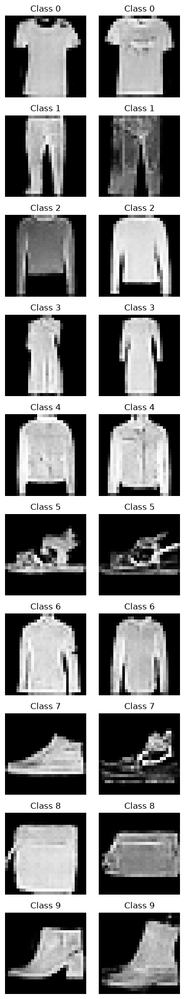

📈 Epoch 35 Summary:
   Train D Loss: 1.3703, Val D Loss: 1.3759
   Train G Loss: 0.7167, Val G Loss: 0.7452

📊 Epoch 36/200
----------------------------------------
Epoch: 36 [0/60000 (0%)]	D_loss: 1.370115	G_loss: 0.697015
Epoch: 36 [6400/60000 (11%)]	D_loss: 1.359335	G_loss: 0.705790
Epoch: 36 [12800/60000 (21%)]	D_loss: 1.355819	G_loss: 0.728874
Epoch: 36 [19200/60000 (32%)]	D_loss: 1.369403	G_loss: 0.711186
Epoch: 36 [25600/60000 (43%)]	D_loss: 1.370320	G_loss: 0.719680
Epoch: 36 [32000/60000 (53%)]	D_loss: 1.367567	G_loss: 0.713994
Epoch: 36 [38400/60000 (64%)]	D_loss: 1.373305	G_loss: 0.695519
Epoch: 36 [44800/60000 (75%)]	D_loss: 1.369580	G_loss: 0.693311
Epoch: 36 [51200/60000 (85%)]	D_loss: 1.366793	G_loss: 0.711831
Epoch: 36 [57600/60000 (96%)]	D_loss: 1.365531	G_loss: 0.699467
====> Epoch: 36 Train D_loss: 1.3696, Train G_loss: 0.7166
====> Epoch: 36 Val D_loss: 1.3707, Val G_loss: 0.7408
📈 Epoch 36 Summary:
   Train D Loss: 1.3696, Val D Loss: 1.3707
   Train G Loss: 0.7166

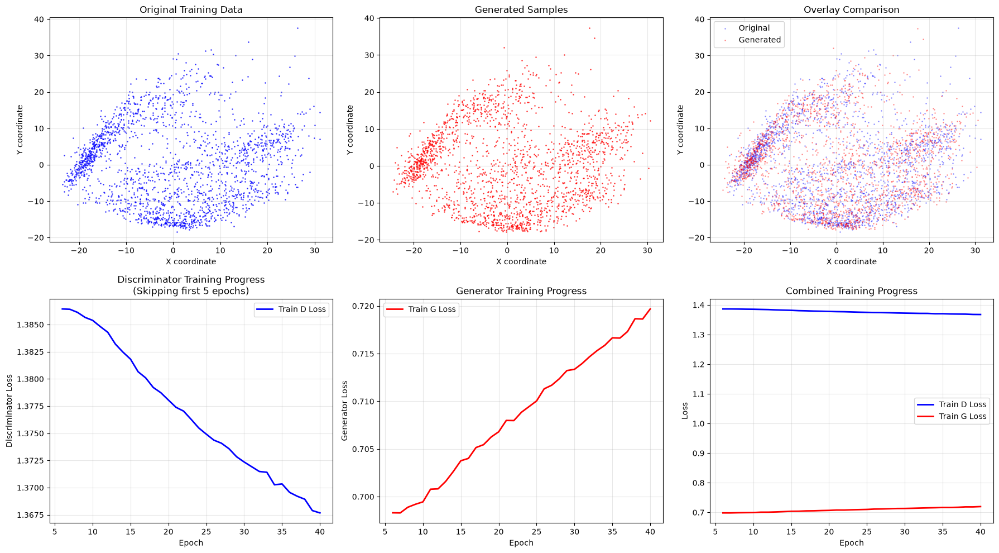

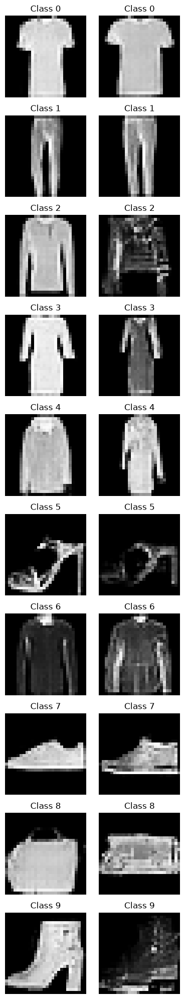

📈 Epoch 40 Summary:
   Train D Loss: 1.3677, Val D Loss: 1.3745
   Train G Loss: 0.7197, Val G Loss: 0.7036

📊 Epoch 41/200
----------------------------------------
Epoch: 41 [0/60000 (0%)]	D_loss: 1.358164	G_loss: 0.729900
Epoch: 41 [6400/60000 (11%)]	D_loss: 1.366436	G_loss: 0.709809
Epoch: 41 [12800/60000 (21%)]	D_loss: 1.357190	G_loss: 0.696867
Epoch: 41 [19200/60000 (32%)]	D_loss: 1.365360	G_loss: 0.721934
Epoch: 41 [25600/60000 (43%)]	D_loss: 1.366883	G_loss: 0.723369
Epoch: 41 [32000/60000 (53%)]	D_loss: 1.363546	G_loss: 0.706115
Epoch: 41 [38400/60000 (64%)]	D_loss: 1.370569	G_loss: 0.712740
Epoch: 41 [44800/60000 (75%)]	D_loss: 1.364959	G_loss: 0.714573
Epoch: 41 [51200/60000 (85%)]	D_loss: 1.358166	G_loss: 0.732148
Epoch: 41 [57600/60000 (96%)]	D_loss: 1.358856	G_loss: 0.713970
====> Epoch: 41 Train D_loss: 1.3673, Train G_loss: 0.7205
====> Epoch: 41 Val D_loss: 1.3722, Val G_loss: 0.6679
📈 Epoch 41 Summary:
   Train D Loss: 1.3673, Val D Loss: 1.3722
   Train G Loss: 0.7205

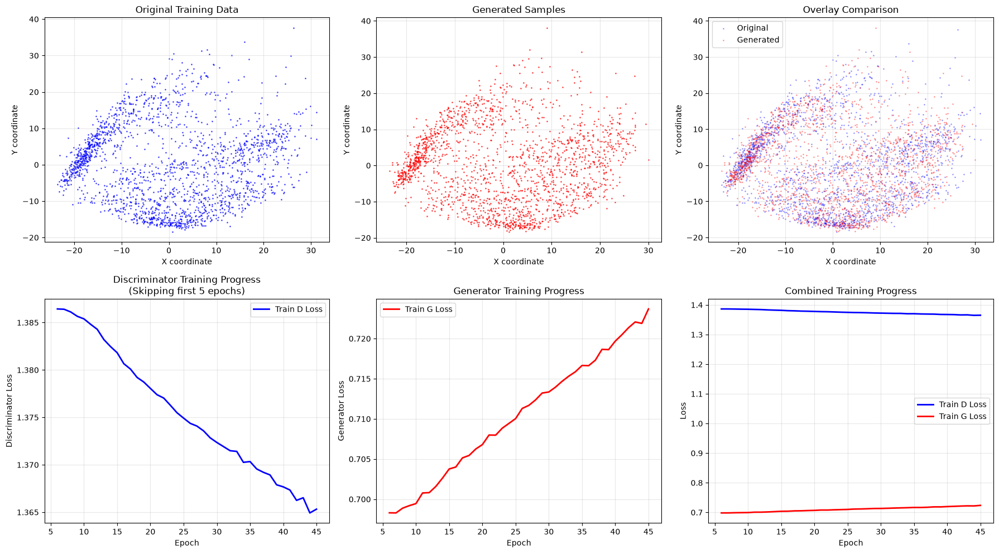

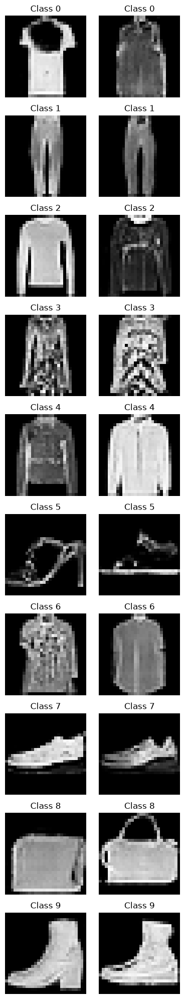

📈 Epoch 45 Summary:
   Train D Loss: 1.3653, Val D Loss: 1.3728
   Train G Loss: 0.7237, Val G Loss: 0.6866

📊 Epoch 46/200
----------------------------------------
Epoch: 46 [0/60000 (0%)]	D_loss: 1.346099	G_loss: 0.726083
Epoch: 46 [6400/60000 (11%)]	D_loss: 1.353975	G_loss: 0.727946
Epoch: 46 [12800/60000 (21%)]	D_loss: 1.356477	G_loss: 0.708597
Epoch: 46 [19200/60000 (32%)]	D_loss: 1.360692	G_loss: 0.711613
Epoch: 46 [25600/60000 (43%)]	D_loss: 1.365217	G_loss: 0.711566
Epoch: 46 [32000/60000 (53%)]	D_loss: 1.345278	G_loss: 0.716891
Epoch: 46 [38400/60000 (64%)]	D_loss: 1.358915	G_loss: 0.715169
Epoch: 46 [44800/60000 (75%)]	D_loss: 1.357302	G_loss: 0.716404
Epoch: 46 [51200/60000 (85%)]	D_loss: 1.385578	G_loss: 0.716180
Epoch: 46 [57600/60000 (96%)]	D_loss: 1.366498	G_loss: 0.735241
====> Epoch: 46 Train D_loss: 1.3646, Train G_loss: 0.7235
====> Epoch: 46 Val D_loss: 1.3643, Val G_loss: 0.7099
📈 Epoch 46 Summary:
   Train D Loss: 1.3646, Val D Loss: 1.3643
   Train G Loss: 0.7235

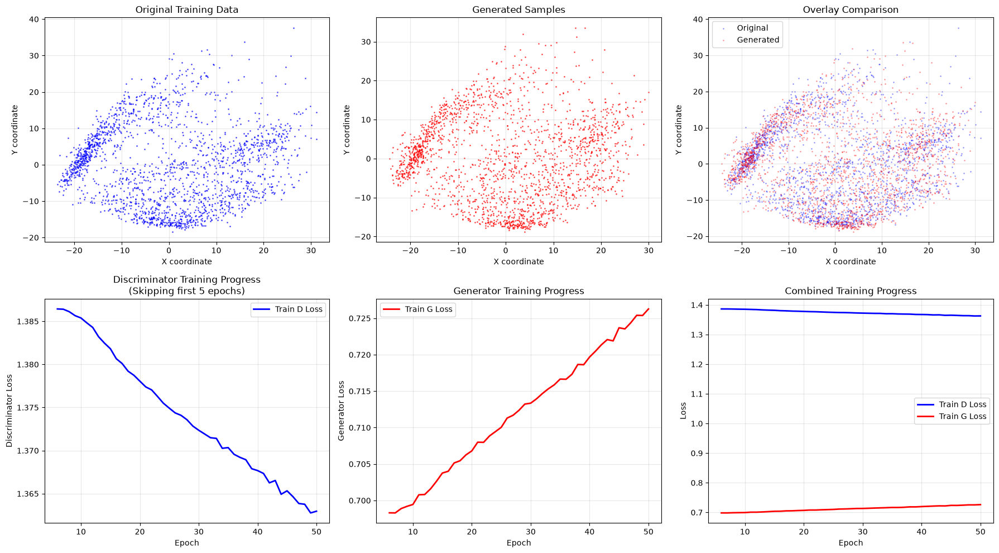

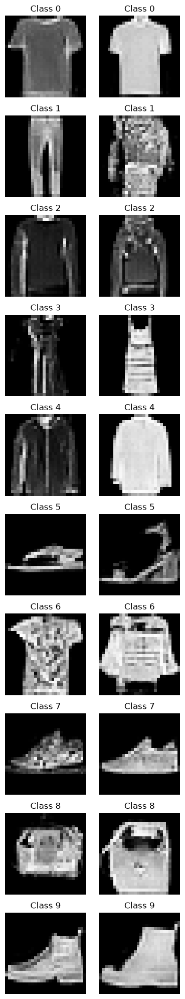

📈 Epoch 50 Summary:
   Train D Loss: 1.3630, Val D Loss: 1.3732
   Train G Loss: 0.7263, Val G Loss: 0.7427

📊 Epoch 51/200
----------------------------------------
Epoch: 51 [0/60000 (0%)]	D_loss: 1.365835	G_loss: 0.715947
Epoch: 51 [6400/60000 (11%)]	D_loss: 1.359771	G_loss: 0.737394
Epoch: 51 [12800/60000 (21%)]	D_loss: 1.356510	G_loss: 0.712616
Epoch: 51 [19200/60000 (32%)]	D_loss: 1.359403	G_loss: 0.722791
Epoch: 51 [25600/60000 (43%)]	D_loss: 1.363738	G_loss: 0.715316
Epoch: 51 [32000/60000 (53%)]	D_loss: 1.398607	G_loss: 0.730025
Epoch: 51 [38400/60000 (64%)]	D_loss: 1.366571	G_loss: 0.718169
Epoch: 51 [44800/60000 (75%)]	D_loss: 1.402053	G_loss: 0.730369
Epoch: 51 [51200/60000 (85%)]	D_loss: 1.356815	G_loss: 0.728021
Epoch: 51 [57600/60000 (96%)]	D_loss: 1.344393	G_loss: 0.727649
====> Epoch: 51 Train D_loss: 1.3624, Train G_loss: 0.7269
====> Epoch: 51 Val D_loss: 1.3870, Val G_loss: 0.7701
📈 Epoch 51 Summary:
   Train D Loss: 1.3624, Val D Loss: 1.3870
   Train G Loss: 0.7269

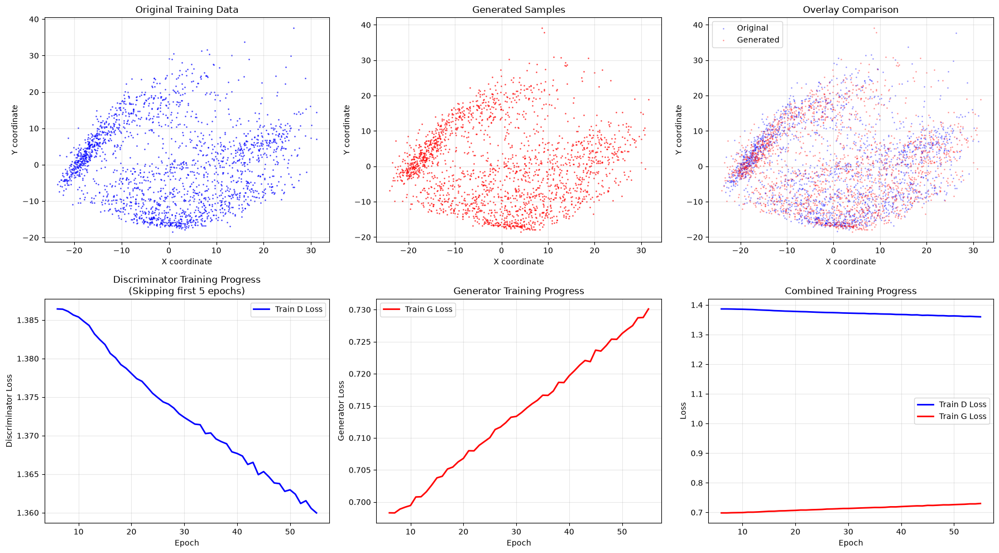

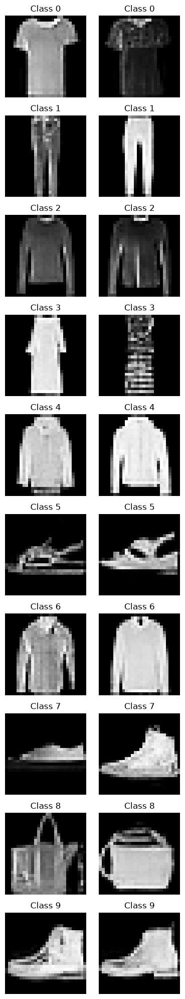

📈 Epoch 55 Summary:
   Train D Loss: 1.3600, Val D Loss: 1.3708
   Train G Loss: 0.7301, Val G Loss: 0.7912

📊 Epoch 56/200
----------------------------------------
Epoch: 56 [0/60000 (0%)]	D_loss: 1.350068	G_loss: 0.726009
Epoch: 56 [6400/60000 (11%)]	D_loss: 1.373588	G_loss: 0.698971
Epoch: 56 [12800/60000 (21%)]	D_loss: 1.363327	G_loss: 0.740211
Epoch: 56 [19200/60000 (32%)]	D_loss: 1.358606	G_loss: 0.745650
Epoch: 56 [25600/60000 (43%)]	D_loss: 1.356377	G_loss: 0.730037
Epoch: 56 [32000/60000 (53%)]	D_loss: 1.373853	G_loss: 0.724227
Epoch: 56 [38400/60000 (64%)]	D_loss: 1.354243	G_loss: 0.715166
Epoch: 56 [44800/60000 (75%)]	D_loss: 1.360580	G_loss: 0.725956
Epoch: 56 [51200/60000 (85%)]	D_loss: 1.360750	G_loss: 0.729155
Epoch: 56 [57600/60000 (96%)]	D_loss: 1.348450	G_loss: 0.733066
====> Epoch: 56 Train D_loss: 1.3604, Train G_loss: 0.7301
====> Epoch: 56 Val D_loss: 1.3907, Val G_loss: 0.8487
📈 Epoch 56 Summary:
   Train D Loss: 1.3604, Val D Loss: 1.3907
   Train G Loss: 0.7301

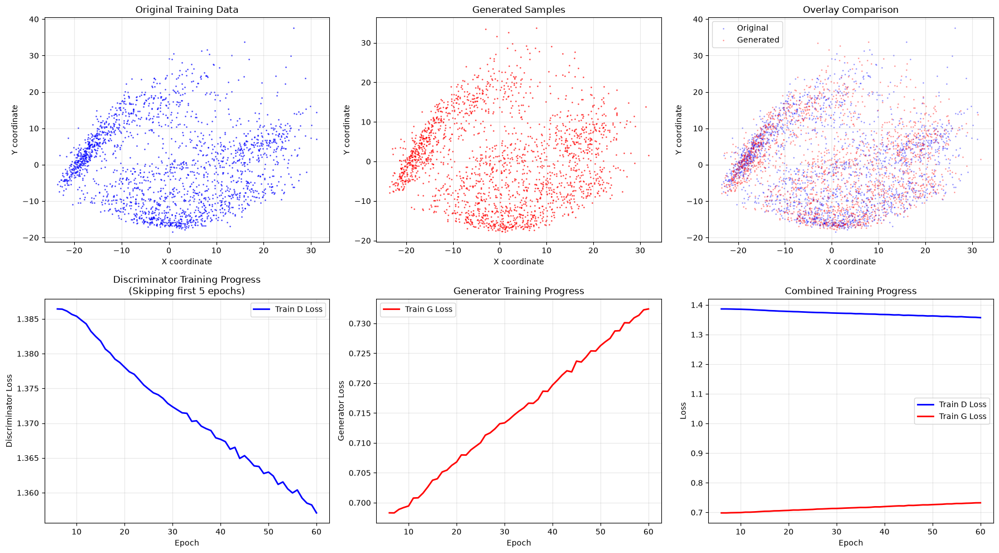

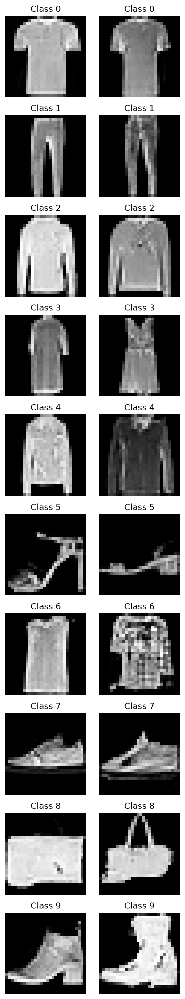

📈 Epoch 60 Summary:
   Train D Loss: 1.3571, Val D Loss: 1.3726
   Train G Loss: 0.7324, Val G Loss: 0.6903

📊 Epoch 61/200
----------------------------------------
Epoch: 61 [0/60000 (0%)]	D_loss: 1.360093	G_loss: 0.722037
Epoch: 61 [6400/60000 (11%)]	D_loss: 1.361857	G_loss: 0.743551
Epoch: 61 [12800/60000 (21%)]	D_loss: 1.369173	G_loss: 0.734290
Epoch: 61 [19200/60000 (32%)]	D_loss: 1.353132	G_loss: 0.756489
Epoch: 61 [25600/60000 (43%)]	D_loss: 1.350719	G_loss: 0.727142
Epoch: 61 [32000/60000 (53%)]	D_loss: 1.352292	G_loss: 0.736244
Epoch: 61 [38400/60000 (64%)]	D_loss: 1.369481	G_loss: 0.725818
Epoch: 61 [44800/60000 (75%)]	D_loss: 1.349210	G_loss: 0.747836
Epoch: 61 [51200/60000 (85%)]	D_loss: 1.357616	G_loss: 0.724772
Epoch: 61 [57600/60000 (96%)]	D_loss: 1.352258	G_loss: 0.745697
====> Epoch: 61 Train D_loss: 1.3576, Train G_loss: 0.7342
====> Epoch: 61 Val D_loss: 1.3725, Val G_loss: 0.7167
📈 Epoch 61 Summary:
   Train D Loss: 1.3576, Val D Loss: 1.3725
   Train G Loss: 0.7342

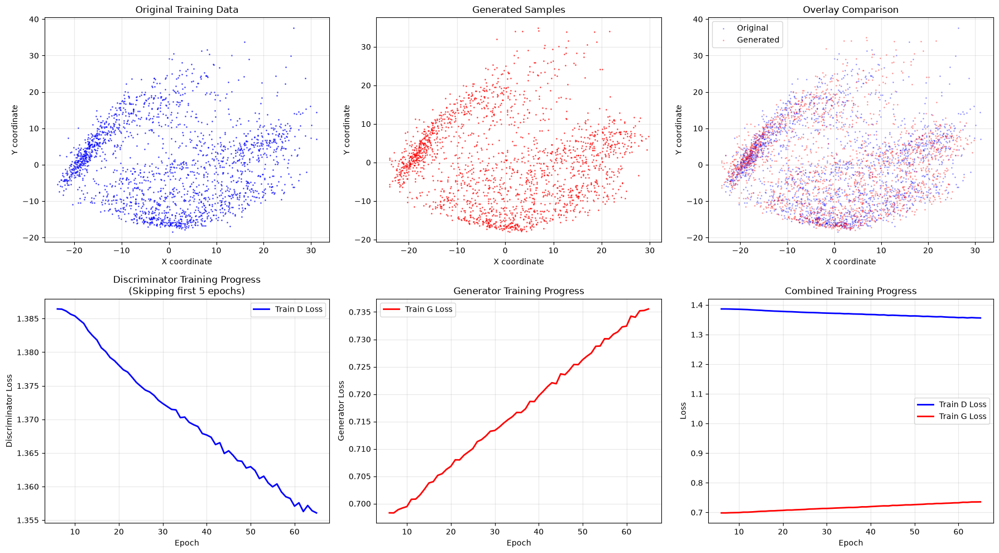

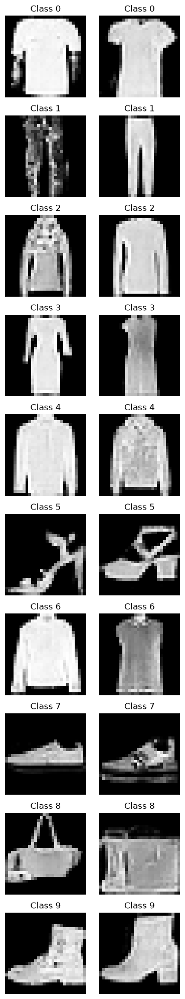

📈 Epoch 65 Summary:
   Train D Loss: 1.3561, Val D Loss: 1.3829
   Train G Loss: 0.7356, Val G Loss: 0.7767

📊 Epoch 66/200
----------------------------------------
Epoch: 66 [0/60000 (0%)]	D_loss: 1.358438	G_loss: 0.743942
Epoch: 66 [6400/60000 (11%)]	D_loss: 1.338533	G_loss: 0.715279
Epoch: 66 [12800/60000 (21%)]	D_loss: 1.357068	G_loss: 0.713079
Epoch: 66 [19200/60000 (32%)]	D_loss: 1.361715	G_loss: 0.733509
Epoch: 66 [25600/60000 (43%)]	D_loss: 1.339767	G_loss: 0.720487
Epoch: 66 [32000/60000 (53%)]	D_loss: 1.351591	G_loss: 0.732691
Epoch: 66 [38400/60000 (64%)]	D_loss: 1.349768	G_loss: 0.732452
Epoch: 66 [44800/60000 (75%)]	D_loss: 1.367547	G_loss: 0.695027
Epoch: 66 [51200/60000 (85%)]	D_loss: 1.352385	G_loss: 0.756526
Epoch: 66 [57600/60000 (96%)]	D_loss: 1.365477	G_loss: 0.741707
====> Epoch: 66 Train D_loss: 1.3555, Train G_loss: 0.7367
====> Epoch: 66 Val D_loss: 1.3983, Val G_loss: 0.8769
📈 Epoch 66 Summary:
   Train D Loss: 1.3555, Val D Loss: 1.3983
   Train G Loss: 0.7367

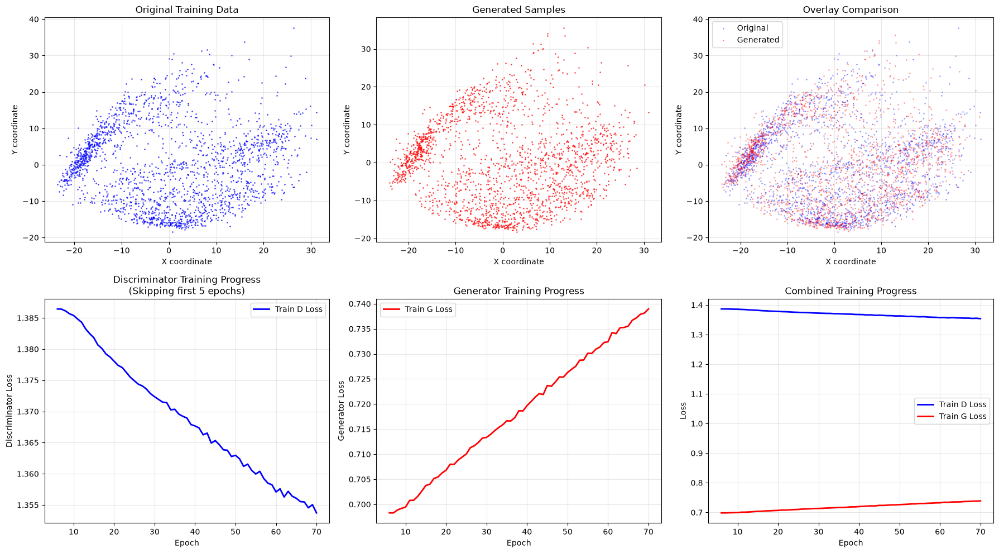

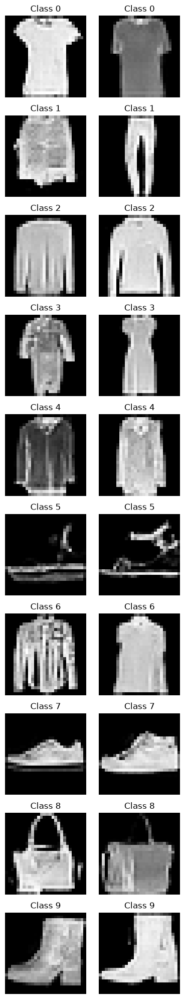

📈 Epoch 70 Summary:
   Train D Loss: 1.3537, Val D Loss: 1.3774
   Train G Loss: 0.7390, Val G Loss: 0.7081

📊 Epoch 71/200
----------------------------------------
Epoch: 71 [0/60000 (0%)]	D_loss: 1.355416	G_loss: 0.761091
Epoch: 71 [6400/60000 (11%)]	D_loss: 1.338940	G_loss: 0.728238
Epoch: 71 [12800/60000 (21%)]	D_loss: 1.360389	G_loss: 0.744446
Epoch: 71 [19200/60000 (32%)]	D_loss: 1.349483	G_loss: 0.713449
Epoch: 71 [25600/60000 (43%)]	D_loss: 1.356560	G_loss: 0.757696
Epoch: 71 [32000/60000 (53%)]	D_loss: 1.364141	G_loss: 0.769665
Epoch: 71 [38400/60000 (64%)]	D_loss: 1.365775	G_loss: 0.721109
Epoch: 71 [44800/60000 (75%)]	D_loss: 1.359702	G_loss: 0.779765
Epoch: 71 [51200/60000 (85%)]	D_loss: 1.346782	G_loss: 0.745190
Epoch: 71 [57600/60000 (96%)]	D_loss: 1.344024	G_loss: 0.746461
====> Epoch: 71 Train D_loss: 1.3530, Train G_loss: 0.7395
====> Epoch: 71 Val D_loss: 1.3887, Val G_loss: 0.8407
📈 Epoch 71 Summary:
   Train D Loss: 1.3530, Val D Loss: 1.3887
   Train G Loss: 0.7395

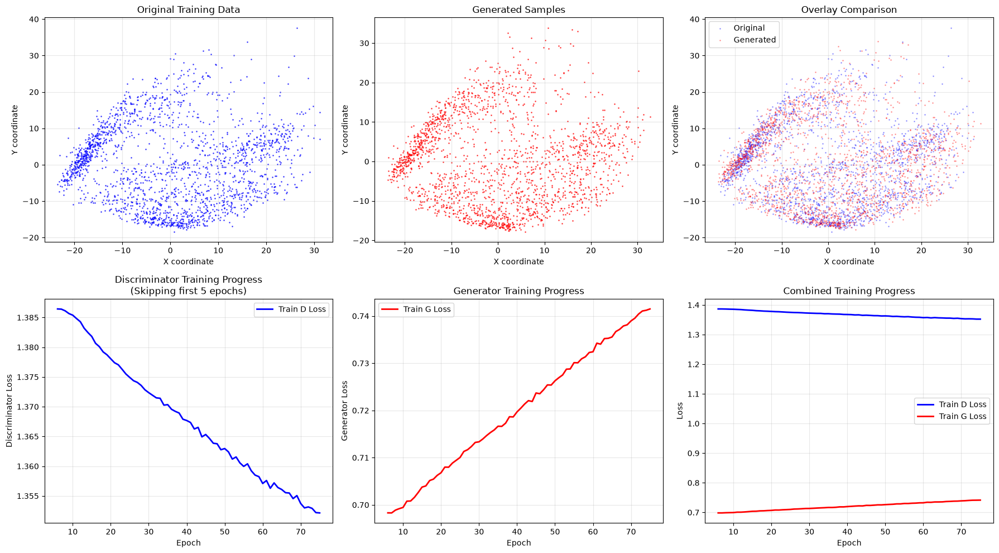

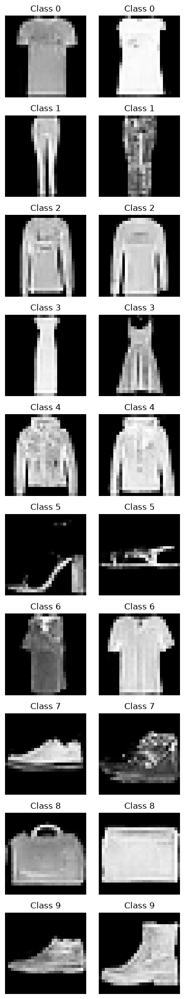

📈 Epoch 75 Summary:
   Train D Loss: 1.3521, Val D Loss: 1.4054
   Train G Loss: 0.7415, Val G Loss: 0.8889

📊 Epoch 76/200
----------------------------------------
Epoch: 76 [0/60000 (0%)]	D_loss: 1.346114	G_loss: 0.755679
Epoch: 76 [6400/60000 (11%)]	D_loss: 1.336679	G_loss: 0.730543
Epoch: 76 [12800/60000 (21%)]	D_loss: 1.370749	G_loss: 0.758023
Epoch: 76 [19200/60000 (32%)]	D_loss: 1.367859	G_loss: 0.760986
Epoch: 76 [25600/60000 (43%)]	D_loss: 1.345475	G_loss: 0.738058
Epoch: 76 [32000/60000 (53%)]	D_loss: 1.345574	G_loss: 0.775650
Epoch: 76 [38400/60000 (64%)]	D_loss: 1.340059	G_loss: 0.780158
Epoch: 76 [44800/60000 (75%)]	D_loss: 1.362404	G_loss: 0.704815
Epoch: 76 [51200/60000 (85%)]	D_loss: 1.376416	G_loss: 0.743575
Epoch: 76 [57600/60000 (96%)]	D_loss: 1.364265	G_loss: 0.764849
====> Epoch: 76 Train D_loss: 1.3519, Train G_loss: 0.7424
====> Epoch: 76 Val D_loss: 1.3794, Val G_loss: 0.6673
📈 Epoch 76 Summary:
   Train D Loss: 1.3519, Val D Loss: 1.3794
   Train G Loss: 0.7424

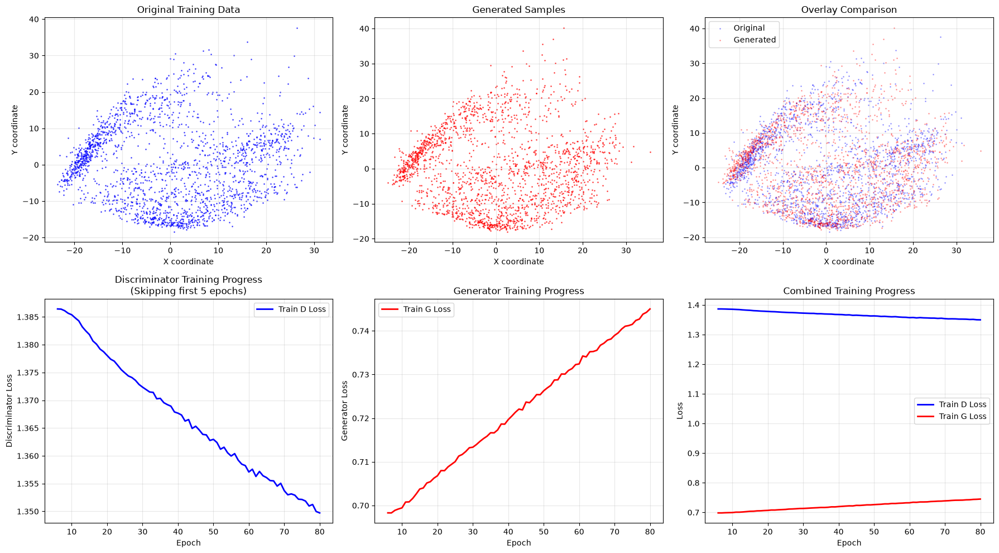

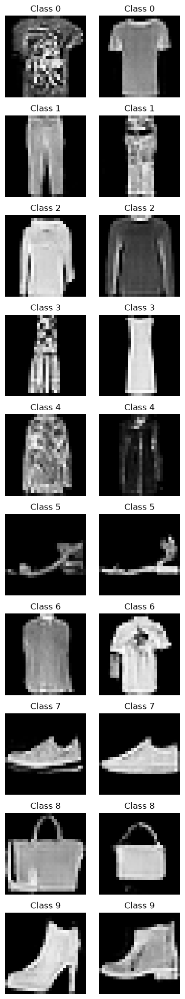

📈 Epoch 80 Summary:
   Train D Loss: 1.3497, Val D Loss: 1.3929
   Train G Loss: 0.7450, Val G Loss: 0.8664

📊 Epoch 81/200
----------------------------------------
Epoch: 81 [0/60000 (0%)]	D_loss: 1.358023	G_loss: 0.763386
Epoch: 81 [6400/60000 (11%)]	D_loss: 1.357649	G_loss: 0.749025
Epoch: 81 [12800/60000 (21%)]	D_loss: 1.354332	G_loss: 0.738292
Epoch: 81 [19200/60000 (32%)]	D_loss: 1.332023	G_loss: 0.753370
Epoch: 81 [25600/60000 (43%)]	D_loss: 1.330938	G_loss: 0.754767
Epoch: 81 [32000/60000 (53%)]	D_loss: 1.363911	G_loss: 0.739493
Epoch: 81 [38400/60000 (64%)]	D_loss: 1.372958	G_loss: 0.751116
Epoch: 81 [44800/60000 (75%)]	D_loss: 1.358729	G_loss: 0.730882
Epoch: 81 [51200/60000 (85%)]	D_loss: 1.340480	G_loss: 0.719753
Epoch: 81 [57600/60000 (96%)]	D_loss: 1.337460	G_loss: 0.742188
====> Epoch: 81 Train D_loss: 1.3495, Train G_loss: 0.7447
====> Epoch: 81 Val D_loss: 1.4015, Val G_loss: 0.5957
📈 Epoch 81 Summary:
   Train D Loss: 1.3495, Val D Loss: 1.4015
   Train G Loss: 0.7447

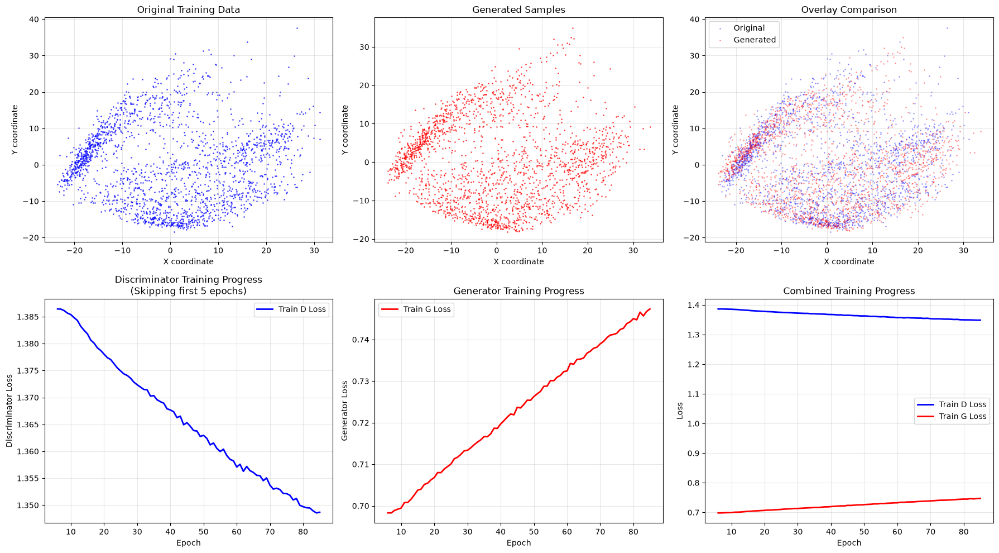

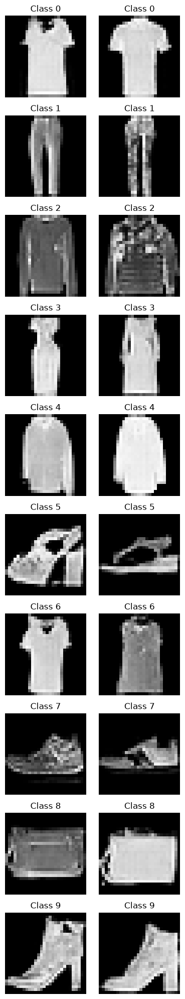

📈 Epoch 85 Summary:
   Train D Loss: 1.3487, Val D Loss: 1.3656
   Train G Loss: 0.7473, Val G Loss: 0.6799

📊 Epoch 86/200
----------------------------------------
Epoch: 86 [0/60000 (0%)]	D_loss: 1.331470	G_loss: 0.728637
Epoch: 86 [6400/60000 (11%)]	D_loss: 1.379632	G_loss: 0.719179
Epoch: 86 [12800/60000 (21%)]	D_loss: 1.351334	G_loss: 0.731398
Epoch: 86 [19200/60000 (32%)]	D_loss: 1.336579	G_loss: 0.712004
Epoch: 86 [25600/60000 (43%)]	D_loss: 1.348882	G_loss: 0.755757
Epoch: 86 [32000/60000 (53%)]	D_loss: 1.317687	G_loss: 0.721419
Epoch: 86 [38400/60000 (64%)]	D_loss: 1.408978	G_loss: 0.768582
Epoch: 86 [44800/60000 (75%)]	D_loss: 1.350877	G_loss: 0.737714
Epoch: 86 [51200/60000 (85%)]	D_loss: 1.358960	G_loss: 0.807864
Epoch: 86 [57600/60000 (96%)]	D_loss: 1.350768	G_loss: 0.754275
====> Epoch: 86 Train D_loss: 1.3483, Train G_loss: 0.7485
====> Epoch: 86 Val D_loss: 1.3841, Val G_loss: 0.6665
📈 Epoch 86 Summary:
   Train D Loss: 1.3483, Val D Loss: 1.3841
   Train G Loss: 0.7485

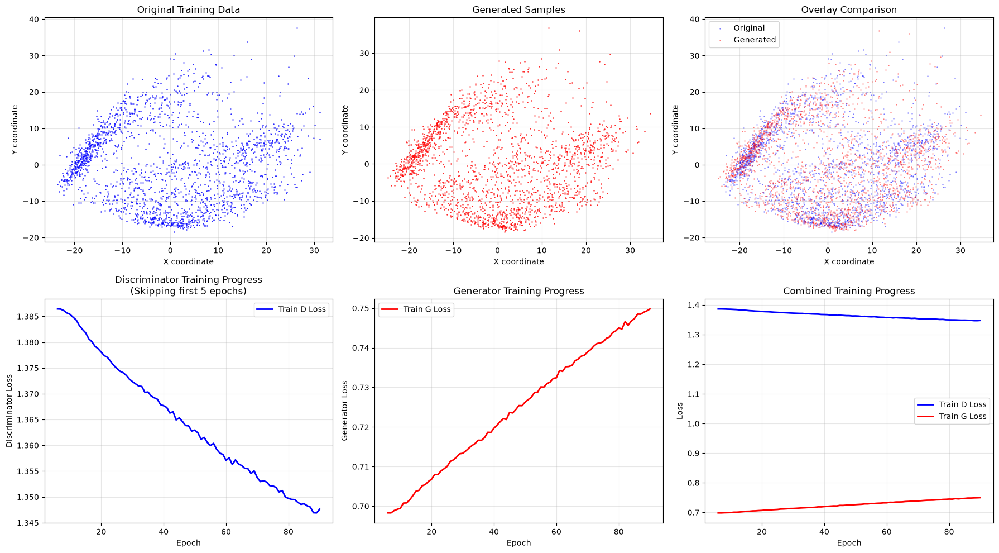

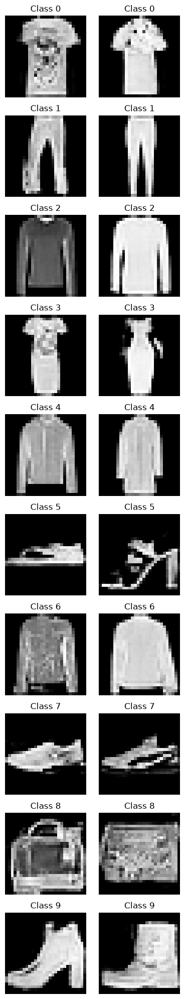

📈 Epoch 90 Summary:
   Train D Loss: 1.3476, Val D Loss: 1.3778
   Train G Loss: 0.7498, Val G Loss: 0.7920

📊 Epoch 91/200
----------------------------------------
Epoch: 91 [0/60000 (0%)]	D_loss: 1.332924	G_loss: 0.757692
Epoch: 91 [6400/60000 (11%)]	D_loss: 1.340823	G_loss: 0.737141
Epoch: 91 [12800/60000 (21%)]	D_loss: 1.386495	G_loss: 0.777362
Epoch: 91 [19200/60000 (32%)]	D_loss: 1.349437	G_loss: 0.742250
Epoch: 91 [25600/60000 (43%)]	D_loss: 1.340573	G_loss: 0.752625
Epoch: 91 [32000/60000 (53%)]	D_loss: 1.357981	G_loss: 0.737832
Epoch: 91 [38400/60000 (64%)]	D_loss: 1.349746	G_loss: 0.747755
Epoch: 91 [44800/60000 (75%)]	D_loss: 1.344658	G_loss: 0.745123
Epoch: 91 [51200/60000 (85%)]	D_loss: 1.350264	G_loss: 0.772184
Epoch: 91 [57600/60000 (96%)]	D_loss: 1.356110	G_loss: 0.749425
====> Epoch: 91 Train D_loss: 1.3464, Train G_loss: 0.7503
====> Epoch: 91 Val D_loss: 1.3776, Val G_loss: 0.6938
📈 Epoch 91 Summary:
   Train D Loss: 1.3464, Val D Loss: 1.3776
   Train G Loss: 0.7503

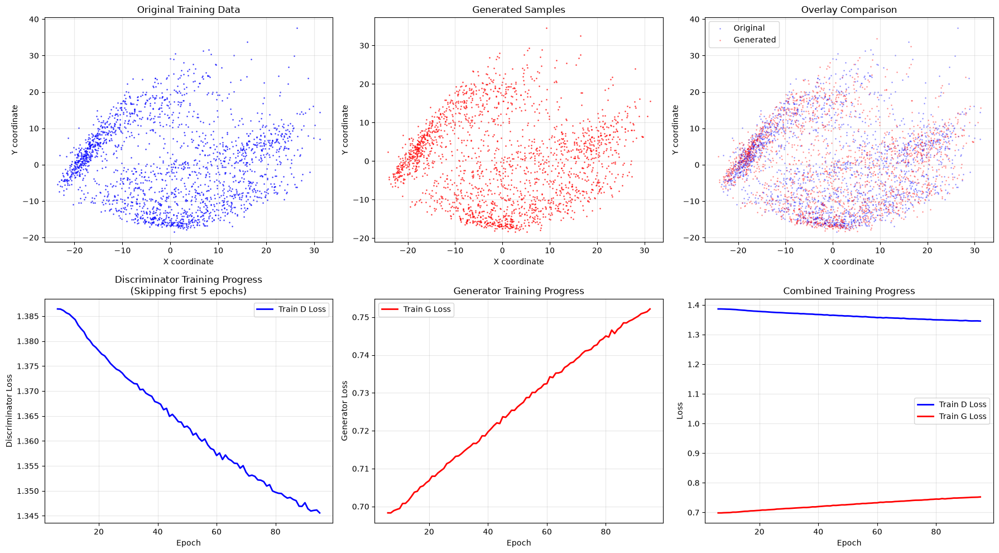

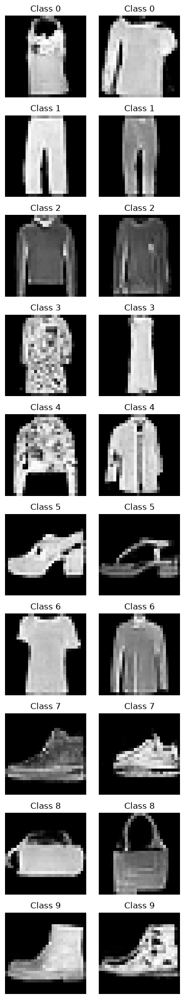

📈 Epoch 95 Summary:
   Train D Loss: 1.3456, Val D Loss: 1.3789
   Train G Loss: 0.7522, Val G Loss: 0.8546

📊 Epoch 96/200
----------------------------------------
Epoch: 96 [0/60000 (0%)]	D_loss: 1.330813	G_loss: 0.742767
Epoch: 96 [6400/60000 (11%)]	D_loss: 1.335872	G_loss: 0.756543
Epoch: 96 [12800/60000 (21%)]	D_loss: 1.336117	G_loss: 0.758239
Epoch: 96 [19200/60000 (32%)]	D_loss: 1.340162	G_loss: 0.741473
Epoch: 96 [25600/60000 (43%)]	D_loss: 1.352163	G_loss: 0.758132
Epoch: 96 [32000/60000 (53%)]	D_loss: 1.336191	G_loss: 0.765405
Epoch: 96 [38400/60000 (64%)]	D_loss: 1.366319	G_loss: 0.726743
Epoch: 96 [44800/60000 (75%)]	D_loss: 1.330080	G_loss: 0.762532
Epoch: 96 [51200/60000 (85%)]	D_loss: 1.350133	G_loss: 0.725258
Epoch: 96 [57600/60000 (96%)]	D_loss: 1.341021	G_loss: 0.760456
====> Epoch: 96 Train D_loss: 1.3464, Train G_loss: 0.7533
====> Epoch: 96 Val D_loss: 1.4110, Val G_loss: 0.6408
📈 Epoch 96 Summary:
   Train D Loss: 1.3464, Val D Loss: 1.4110
   Train G Loss: 0.7533

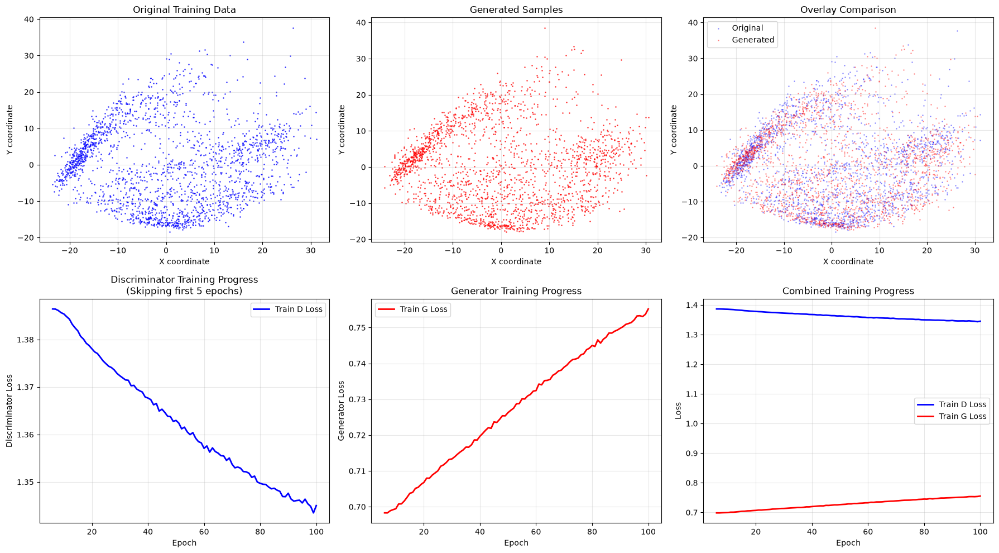

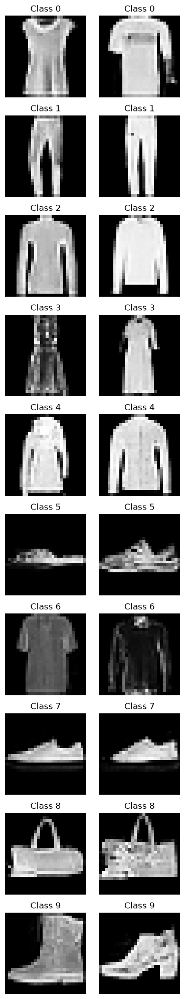

📈 Epoch 100 Summary:
   Train D Loss: 1.3450, Val D Loss: 1.4326
   Train G Loss: 0.7552, Val G Loss: 0.6022

📊 Epoch 101/200
----------------------------------------
Epoch: 101 [0/60000 (0%)]	D_loss: 1.360723	G_loss: 0.722124
Epoch: 101 [6400/60000 (11%)]	D_loss: 1.347282	G_loss: 0.721789
Epoch: 101 [12800/60000 (21%)]	D_loss: 1.339438	G_loss: 0.762302
Epoch: 101 [19200/60000 (32%)]	D_loss: 1.347396	G_loss: 0.774747
Epoch: 101 [25600/60000 (43%)]	D_loss: 1.343209	G_loss: 0.745486
Epoch: 101 [32000/60000 (53%)]	D_loss: 1.323379	G_loss: 0.746974
Epoch: 101 [38400/60000 (64%)]	D_loss: 1.343739	G_loss: 0.742261
Epoch: 101 [44800/60000 (75%)]	D_loss: 1.362420	G_loss: 0.761331
Epoch: 101 [51200/60000 (85%)]	D_loss: 1.326914	G_loss: 0.777814
Epoch: 101 [57600/60000 (96%)]	D_loss: 1.342077	G_loss: 0.792431
====> Epoch: 101 Train D_loss: 1.3433, Train G_loss: 0.7549
====> Epoch: 101 Val D_loss: 1.3888, Val G_loss: 0.8175
📈 Epoch 101 Summary:
   Train D Loss: 1.3433, Val D Loss: 1.3888
   Train

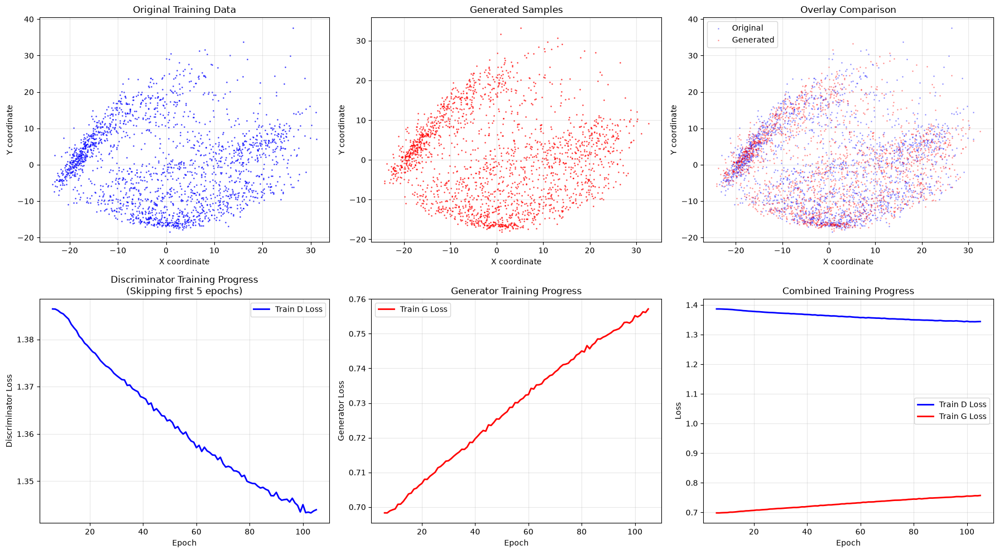

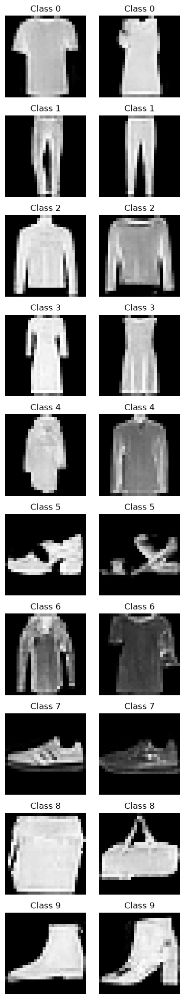

📈 Epoch 105 Summary:
   Train D Loss: 1.3439, Val D Loss: 1.4469
   Train G Loss: 0.7571, Val G Loss: 1.0169

📊 Epoch 106/200
----------------------------------------
Epoch: 106 [0/60000 (0%)]	D_loss: 1.352667	G_loss: 0.762315
Epoch: 106 [6400/60000 (11%)]	D_loss: 1.340677	G_loss: 0.737348
Epoch: 106 [12800/60000 (21%)]	D_loss: 1.344028	G_loss: 0.754252
Epoch: 106 [19200/60000 (32%)]	D_loss: 1.347554	G_loss: 0.740716
Epoch: 106 [25600/60000 (43%)]	D_loss: 1.351815	G_loss: 0.774163
Epoch: 106 [32000/60000 (53%)]	D_loss: 1.327192	G_loss: 0.758233
Epoch: 106 [38400/60000 (64%)]	D_loss: 1.330199	G_loss: 0.746951
Epoch: 106 [44800/60000 (75%)]	D_loss: 1.396160	G_loss: 0.778077
Epoch: 106 [51200/60000 (85%)]	D_loss: 1.335312	G_loss: 0.736088
Epoch: 106 [57600/60000 (96%)]	D_loss: 1.319688	G_loss: 0.726528
====> Epoch: 106 Train D_loss: 1.3416, Train G_loss: 0.7559
====> Epoch: 106 Val D_loss: 1.3750, Val G_loss: 0.6988
📈 Epoch 106 Summary:
   Train D Loss: 1.3416, Val D Loss: 1.3750
   Train

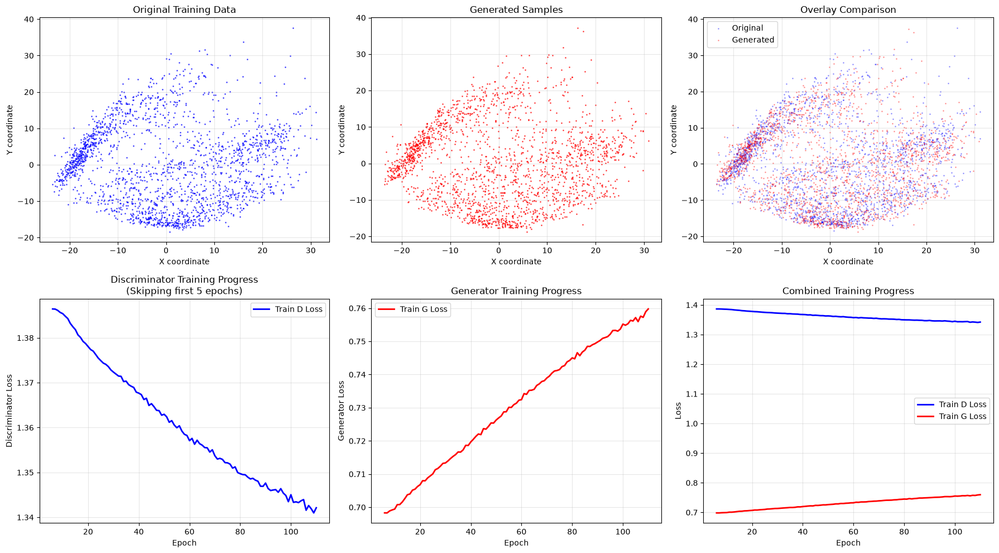

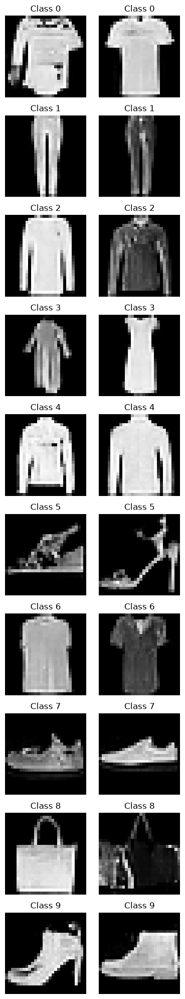

📈 Epoch 110 Summary:
   Train D Loss: 1.3421, Val D Loss: 1.4676
   Train G Loss: 0.7598, Val G Loss: 0.5085

📊 Epoch 111/200
----------------------------------------
Epoch: 111 [0/60000 (0%)]	D_loss: 1.362660	G_loss: 0.763083
Epoch: 111 [6400/60000 (11%)]	D_loss: 1.333821	G_loss: 0.725372
Epoch: 111 [12800/60000 (21%)]	D_loss: 1.362767	G_loss: 0.736210
Epoch: 111 [19200/60000 (32%)]	D_loss: 1.332207	G_loss: 0.747627
Epoch: 111 [25600/60000 (43%)]	D_loss: 1.342449	G_loss: 0.783972
Epoch: 111 [32000/60000 (53%)]	D_loss: 1.330609	G_loss: 0.729039
Epoch: 111 [38400/60000 (64%)]	D_loss: 1.335310	G_loss: 0.790402
Epoch: 111 [44800/60000 (75%)]	D_loss: 1.330488	G_loss: 0.769471
Epoch: 111 [51200/60000 (85%)]	D_loss: 1.348128	G_loss: 0.734360
Epoch: 111 [57600/60000 (96%)]	D_loss: 1.299826	G_loss: 0.782218
====> Epoch: 111 Train D_loss: 1.3408, Train G_loss: 0.7589
====> Epoch: 111 Val D_loss: 1.4061, Val G_loss: 0.5996
📈 Epoch 111 Summary:
   Train D Loss: 1.3408, Val D Loss: 1.4061
   Train

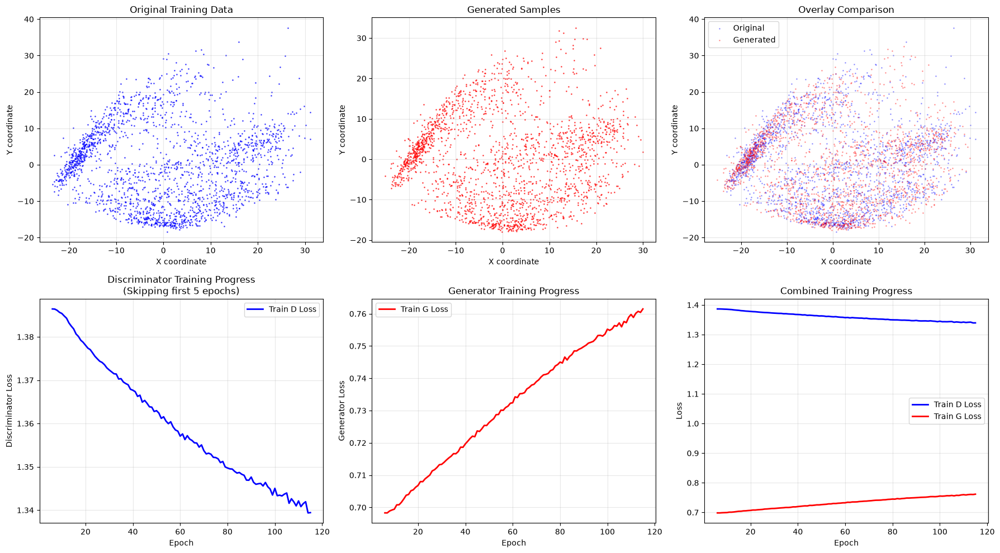

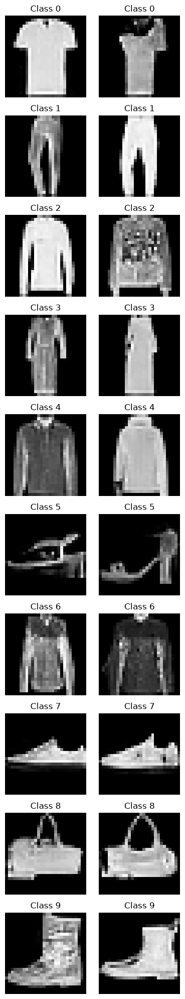

📈 Epoch 115 Summary:
   Train D Loss: 1.3394, Val D Loss: 1.3761
   Train G Loss: 0.7615, Val G Loss: 0.8350

📊 Epoch 116/200
----------------------------------------
Epoch: 116 [0/60000 (0%)]	D_loss: 1.326098	G_loss: 0.761240
Epoch: 116 [6400/60000 (11%)]	D_loss: 1.334748	G_loss: 0.783261
Epoch: 116 [12800/60000 (21%)]	D_loss: 1.380479	G_loss: 0.796137
Epoch: 116 [19200/60000 (32%)]	D_loss: 1.312642	G_loss: 0.771284
Epoch: 116 [25600/60000 (43%)]	D_loss: 1.323261	G_loss: 0.789446
Epoch: 116 [32000/60000 (53%)]	D_loss: 1.337791	G_loss: 0.773295
Epoch: 116 [38400/60000 (64%)]	D_loss: 1.338241	G_loss: 0.741972
Epoch: 116 [44800/60000 (75%)]	D_loss: 1.315876	G_loss: 0.726885
Epoch: 116 [51200/60000 (85%)]	D_loss: 1.358160	G_loss: 0.723880
Epoch: 116 [57600/60000 (96%)]	D_loss: 1.336646	G_loss: 0.767242
====> Epoch: 116 Train D_loss: 1.3406, Train G_loss: 0.7620
====> Epoch: 116 Val D_loss: 1.3834, Val G_loss: 0.7361
📈 Epoch 116 Summary:
   Train D Loss: 1.3406, Val D Loss: 1.3834
   Train

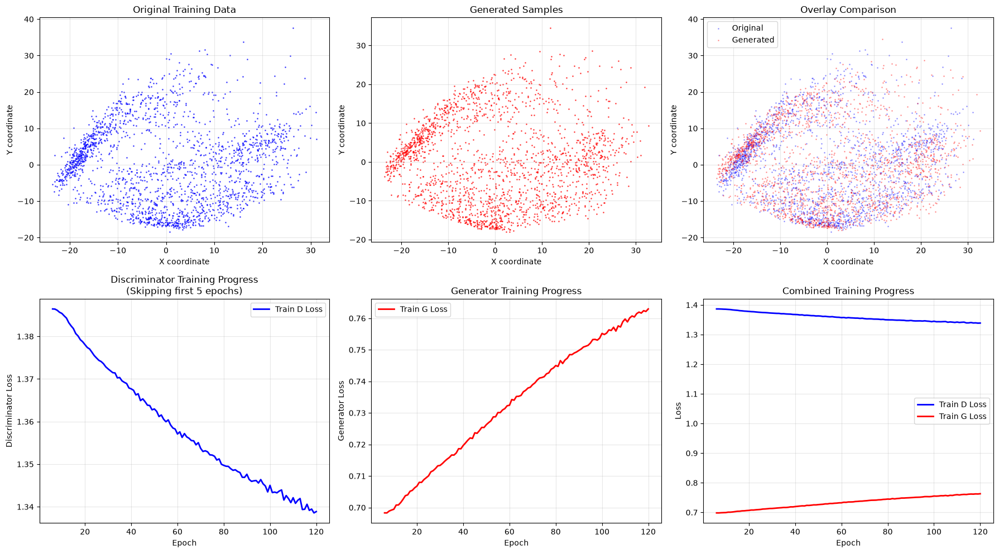

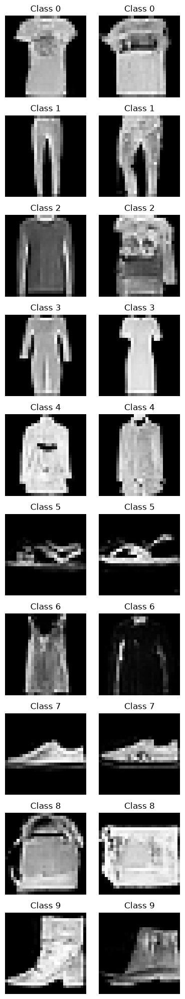

📈 Epoch 120 Summary:
   Train D Loss: 1.3389, Val D Loss: 1.3994
   Train G Loss: 0.7630, Val G Loss: 0.8917

📊 Epoch 121/200
----------------------------------------
Epoch: 121 [0/60000 (0%)]	D_loss: 1.334250	G_loss: 0.737077
Epoch: 121 [6400/60000 (11%)]	D_loss: 1.326966	G_loss: 0.756437
Epoch: 121 [12800/60000 (21%)]	D_loss: 1.332335	G_loss: 0.759584
Epoch: 121 [19200/60000 (32%)]	D_loss: 1.324605	G_loss: 0.805044
Epoch: 121 [25600/60000 (43%)]	D_loss: 1.363403	G_loss: 0.749798
Epoch: 121 [32000/60000 (53%)]	D_loss: 1.329665	G_loss: 0.805365
Epoch: 121 [38400/60000 (64%)]	D_loss: 1.341441	G_loss: 0.760051
Epoch: 121 [44800/60000 (75%)]	D_loss: 1.338907	G_loss: 0.778614
Epoch: 121 [51200/60000 (85%)]	D_loss: 1.328759	G_loss: 0.751494
Epoch: 121 [57600/60000 (96%)]	D_loss: 1.358530	G_loss: 0.804639
====> Epoch: 121 Train D_loss: 1.3379, Train G_loss: 0.7634
====> Epoch: 121 Val D_loss: 1.3927, Val G_loss: 0.7524
📈 Epoch 121 Summary:
   Train D Loss: 1.3379, Val D Loss: 1.3927
   Train

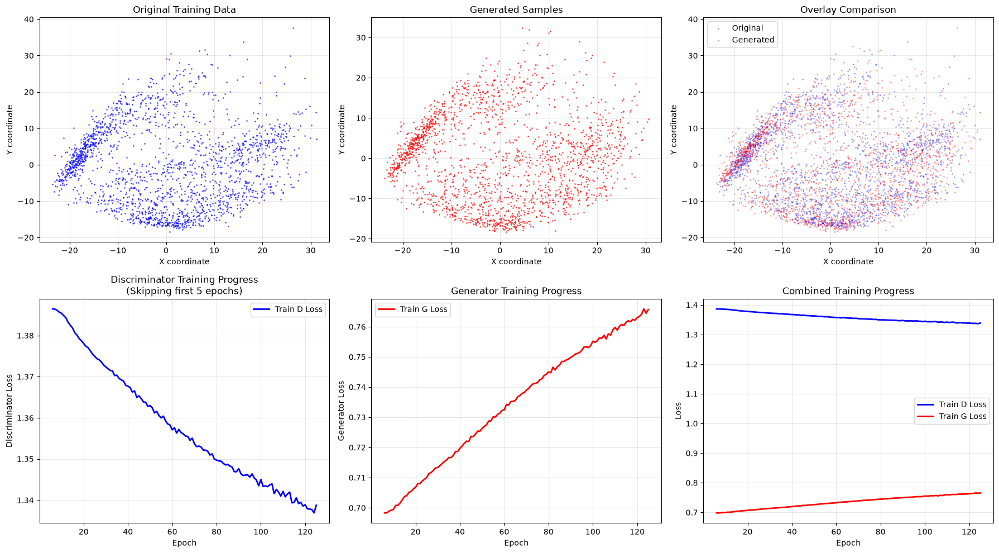

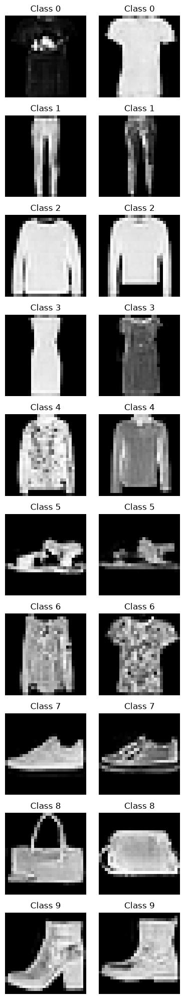

📈 Epoch 125 Summary:
   Train D Loss: 1.3388, Val D Loss: 1.4118
   Train G Loss: 0.7657, Val G Loss: 0.9252

📊 Epoch 126/200
----------------------------------------
Epoch: 126 [0/60000 (0%)]	D_loss: 1.335178	G_loss: 0.741238
Epoch: 126 [6400/60000 (11%)]	D_loss: 1.340700	G_loss: 0.742093
Epoch: 126 [12800/60000 (21%)]	D_loss: 1.338215	G_loss: 0.727937
Epoch: 126 [19200/60000 (32%)]	D_loss: 1.338964	G_loss: 0.745714
Epoch: 126 [25600/60000 (43%)]	D_loss: 1.310409	G_loss: 0.785098
Epoch: 126 [32000/60000 (53%)]	D_loss: 1.313851	G_loss: 0.766040
Epoch: 126 [38400/60000 (64%)]	D_loss: 1.321026	G_loss: 0.756892
Epoch: 126 [44800/60000 (75%)]	D_loss: 1.350027	G_loss: 0.762300
Epoch: 126 [51200/60000 (85%)]	D_loss: 1.317442	G_loss: 0.807156
Epoch: 126 [57600/60000 (96%)]	D_loss: 1.332011	G_loss: 0.769159
====> Epoch: 126 Train D_loss: 1.3361, Train G_loss: 0.7650
====> Epoch: 126 Val D_loss: 1.3901, Val G_loss: 0.6366
📈 Epoch 126 Summary:
   Train D Loss: 1.3361, Val D Loss: 1.3901
   Train

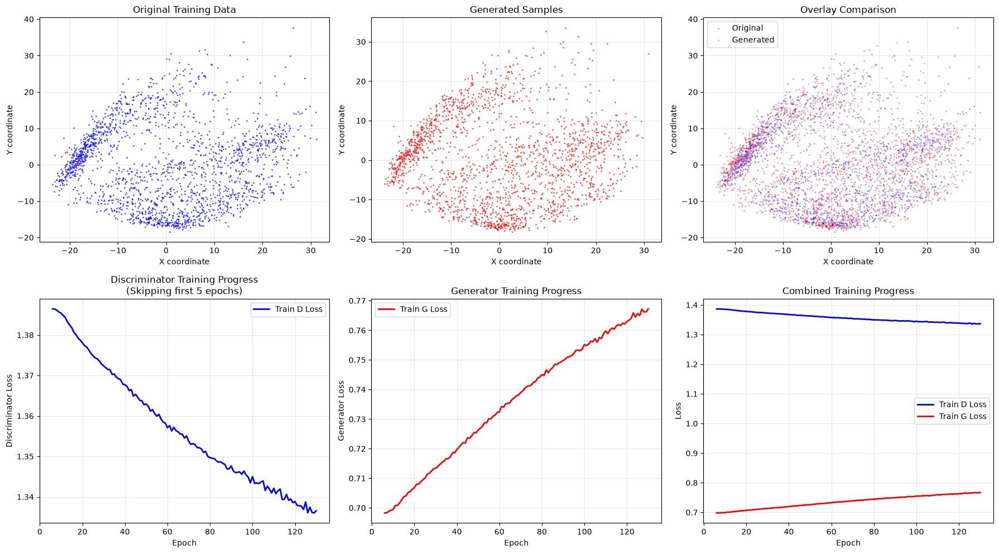

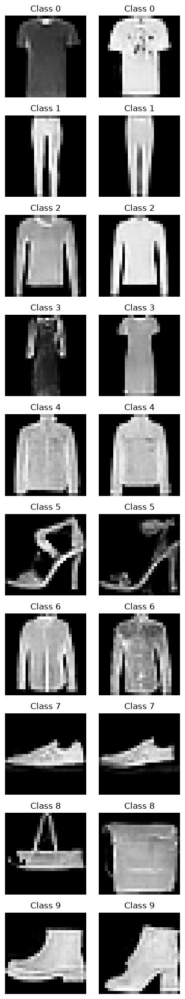

📈 Epoch 130 Summary:
   Train D Loss: 1.3366, Val D Loss: 1.4006
   Train G Loss: 0.7672, Val G Loss: 0.6778

📊 Epoch 131/200
----------------------------------------
Epoch: 131 [0/60000 (0%)]	D_loss: 1.319849	G_loss: 0.806054
Epoch: 131 [6400/60000 (11%)]	D_loss: 1.331198	G_loss: 0.770221
Epoch: 131 [12800/60000 (21%)]	D_loss: 1.332248	G_loss: 0.763587
Epoch: 131 [19200/60000 (32%)]	D_loss: 1.322097	G_loss: 0.774205
Epoch: 131 [25600/60000 (43%)]	D_loss: 1.313519	G_loss: 0.766787
Epoch: 131 [32000/60000 (53%)]	D_loss: 1.355524	G_loss: 0.776564
Epoch: 131 [38400/60000 (64%)]	D_loss: 1.347708	G_loss: 0.778705
Epoch: 131 [44800/60000 (75%)]	D_loss: 1.367275	G_loss: 0.753475
Epoch: 131 [51200/60000 (85%)]	D_loss: 1.342063	G_loss: 0.760500
Epoch: 131 [57600/60000 (96%)]	D_loss: 1.321985	G_loss: 0.774863
====> Epoch: 131 Train D_loss: 1.3353, Train G_loss: 0.7677
====> Epoch: 131 Val D_loss: 1.3737, Val G_loss: 0.7034
📈 Epoch 131 Summary:
   Train D Loss: 1.3353, Val D Loss: 1.3737
   Train

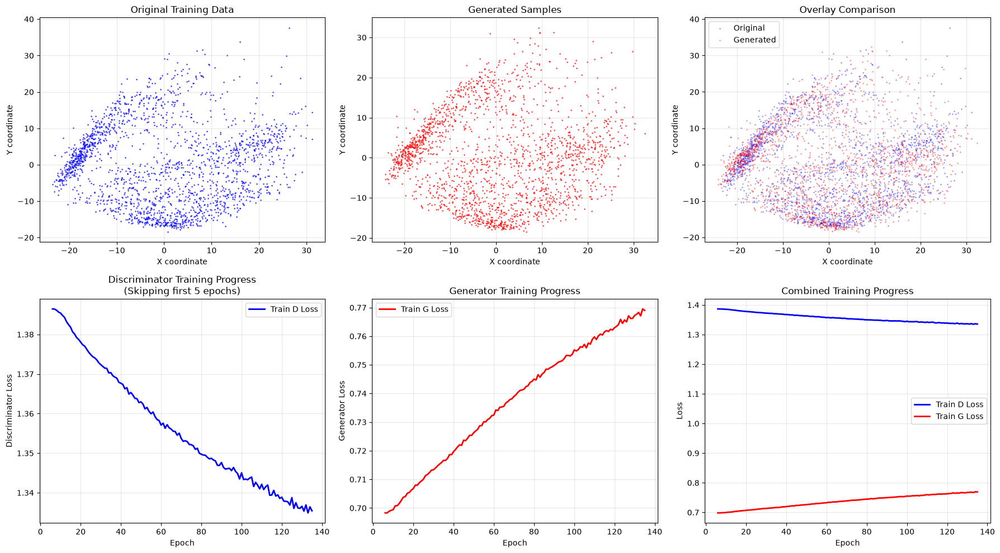

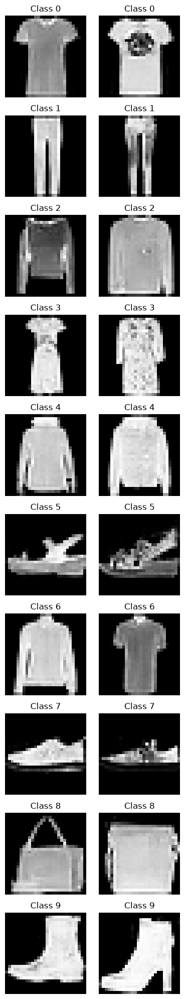

📈 Epoch 135 Summary:
   Train D Loss: 1.3354, Val D Loss: 1.3894
   Train G Loss: 0.7690, Val G Loss: 0.8136

📊 Epoch 136/200
----------------------------------------
Epoch: 136 [0/60000 (0%)]	D_loss: 1.279654	G_loss: 0.815879
Epoch: 136 [6400/60000 (11%)]	D_loss: 1.346227	G_loss: 0.769927
Epoch: 136 [12800/60000 (21%)]	D_loss: 1.345976	G_loss: 0.816632
Epoch: 136 [19200/60000 (32%)]	D_loss: 1.308535	G_loss: 0.791886
Epoch: 136 [25600/60000 (43%)]	D_loss: 1.334585	G_loss: 0.762996
Epoch: 136 [32000/60000 (53%)]	D_loss: 1.369910	G_loss: 0.729620
Epoch: 136 [38400/60000 (64%)]	D_loss: 1.368433	G_loss: 0.807356
Epoch: 136 [44800/60000 (75%)]	D_loss: 1.328812	G_loss: 0.792286
Epoch: 136 [51200/60000 (85%)]	D_loss: 1.357241	G_loss: 0.740057
Epoch: 136 [57600/60000 (96%)]	D_loss: 1.335673	G_loss: 0.797803
====> Epoch: 136 Train D_loss: 1.3356, Train G_loss: 0.7696
====> Epoch: 136 Val D_loss: 1.3976, Val G_loss: 0.6372
📈 Epoch 136 Summary:
   Train D Loss: 1.3356, Val D Loss: 1.3976
   Train

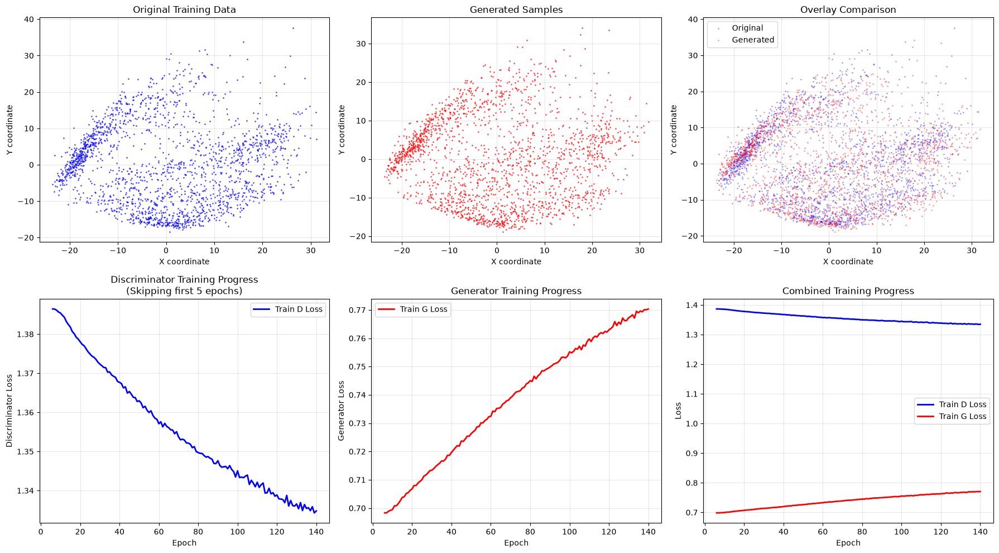

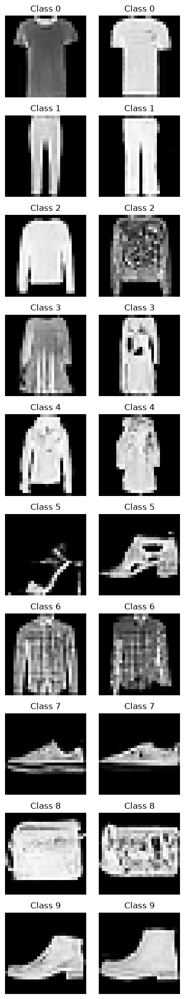

📈 Epoch 140 Summary:
   Train D Loss: 1.3348, Val D Loss: 1.4015
   Train G Loss: 0.7703, Val G Loss: 0.8089

📊 Epoch 141/200
----------------------------------------
Epoch: 141 [0/60000 (0%)]	D_loss: 1.363852	G_loss: 0.781251
Epoch: 141 [6400/60000 (11%)]	D_loss: 1.335846	G_loss: 0.760580
Epoch: 141 [12800/60000 (21%)]	D_loss: 1.323182	G_loss: 0.754167
Epoch: 141 [19200/60000 (32%)]	D_loss: 1.309605	G_loss: 0.812549
Epoch: 141 [25600/60000 (43%)]	D_loss: 1.354307	G_loss: 0.770283
Epoch: 141 [32000/60000 (53%)]	D_loss: 1.314205	G_loss: 0.769448
Epoch: 141 [38400/60000 (64%)]	D_loss: 1.339230	G_loss: 0.756740
Epoch: 141 [44800/60000 (75%)]	D_loss: 1.346405	G_loss: 0.731867
Epoch: 141 [51200/60000 (85%)]	D_loss: 1.322742	G_loss: 0.787294
Epoch: 141 [57600/60000 (96%)]	D_loss: 1.361025	G_loss: 0.761713
====> Epoch: 141 Train D_loss: 1.3348, Train G_loss: 0.7717
====> Epoch: 141 Val D_loss: 1.3916, Val G_loss: 0.6453
📈 Epoch 141 Summary:
   Train D Loss: 1.3348, Val D Loss: 1.3916
   Train

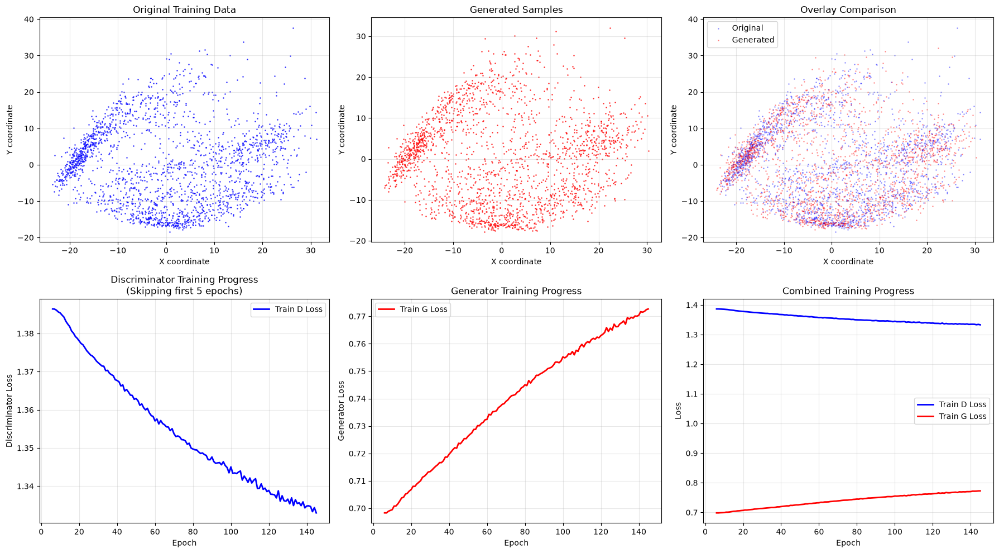

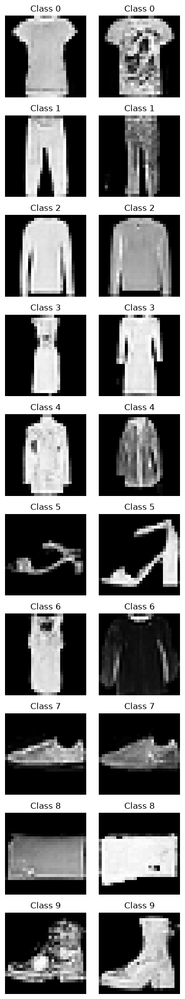

📈 Epoch 145 Summary:
   Train D Loss: 1.3330, Val D Loss: 1.4002
   Train G Loss: 0.7727, Val G Loss: 0.6010

📊 Epoch 146/200
----------------------------------------
Epoch: 146 [0/60000 (0%)]	D_loss: 1.308447	G_loss: 0.802534
Epoch: 146 [6400/60000 (11%)]	D_loss: 1.329999	G_loss: 0.728223
Epoch: 146 [12800/60000 (21%)]	D_loss: 1.337933	G_loss: 0.761000
Epoch: 146 [19200/60000 (32%)]	D_loss: 1.314871	G_loss: 0.800175
Epoch: 146 [25600/60000 (43%)]	D_loss: 1.363606	G_loss: 0.751668
Epoch: 146 [32000/60000 (53%)]	D_loss: 1.325878	G_loss: 0.758005
Epoch: 146 [38400/60000 (64%)]	D_loss: 1.321106	G_loss: 0.810458
Epoch: 146 [44800/60000 (75%)]	D_loss: 1.306803	G_loss: 0.786908
Epoch: 146 [51200/60000 (85%)]	D_loss: 1.317752	G_loss: 0.797849
Epoch: 146 [57600/60000 (96%)]	D_loss: 1.352794	G_loss: 0.801168
====> Epoch: 146 Train D_loss: 1.3325, Train G_loss: 0.7728
====> Epoch: 146 Val D_loss: 1.4037, Val G_loss: 0.8489
📈 Epoch 146 Summary:
   Train D Loss: 1.3325, Val D Loss: 1.4037
   Train

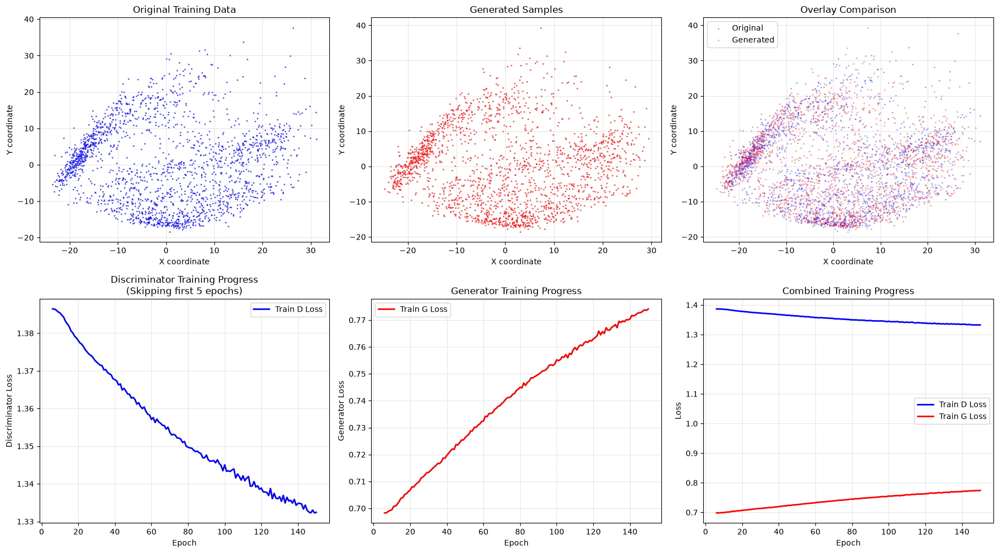

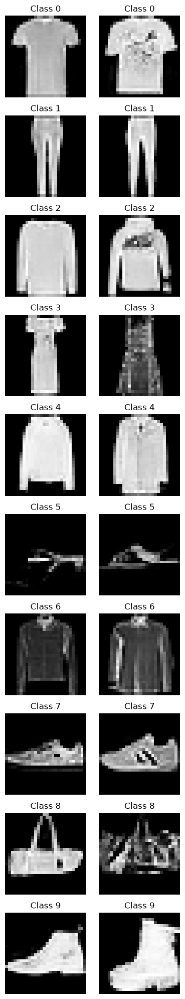

📈 Epoch 150 Summary:
   Train D Loss: 1.3324, Val D Loss: 1.3963
   Train G Loss: 0.7741, Val G Loss: 0.6606

📊 Epoch 151/200
----------------------------------------
Epoch: 151 [0/60000 (0%)]	D_loss: 1.340457	G_loss: 0.758250
Epoch: 151 [6400/60000 (11%)]	D_loss: 1.328330	G_loss: 0.783389
Epoch: 151 [12800/60000 (21%)]	D_loss: 1.325529	G_loss: 0.802196
Epoch: 151 [19200/60000 (32%)]	D_loss: 1.318238	G_loss: 0.760966
Epoch: 151 [25600/60000 (43%)]	D_loss: 1.306034	G_loss: 0.786257
Epoch: 151 [32000/60000 (53%)]	D_loss: 1.334324	G_loss: 0.789392
Epoch: 151 [38400/60000 (64%)]	D_loss: 1.330151	G_loss: 0.747995
Epoch: 151 [44800/60000 (75%)]	D_loss: 1.323657	G_loss: 0.796154
Epoch: 151 [51200/60000 (85%)]	D_loss: 1.320359	G_loss: 0.783989
Epoch: 151 [57600/60000 (96%)]	D_loss: 1.320873	G_loss: 0.750653
====> Epoch: 151 Train D_loss: 1.3313, Train G_loss: 0.7747
====> Epoch: 151 Val D_loss: 1.3839, Val G_loss: 0.6630
📈 Epoch 151 Summary:
   Train D Loss: 1.3313, Val D Loss: 1.3839
   Train

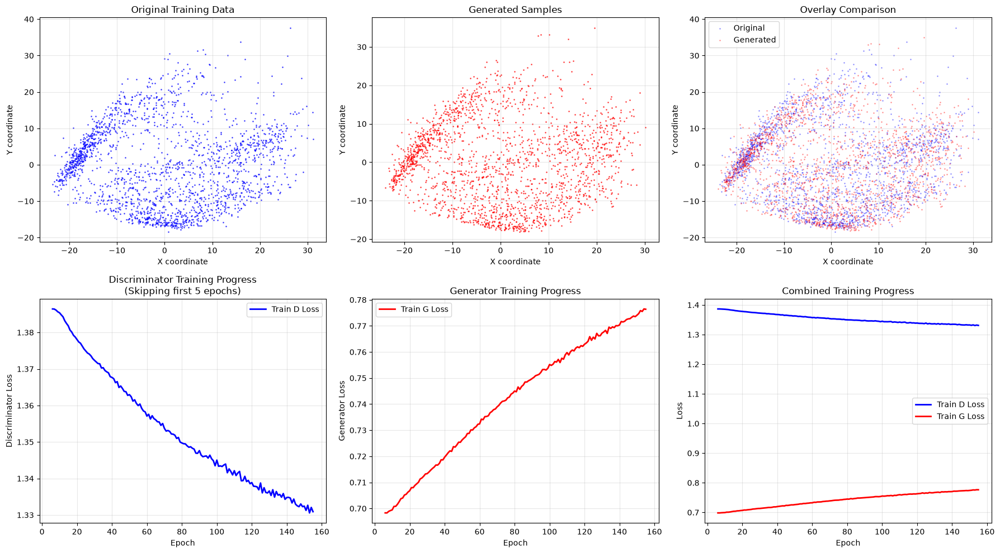

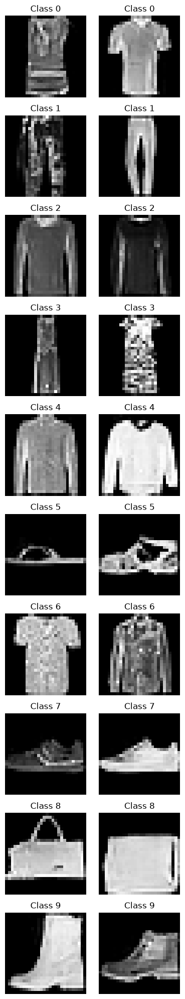

📈 Epoch 155 Summary:
   Train D Loss: 1.3309, Val D Loss: 1.4116
   Train G Loss: 0.7764, Val G Loss: 0.9329

📊 Epoch 156/200
----------------------------------------
Epoch: 156 [0/60000 (0%)]	D_loss: 1.317857	G_loss: 0.748837
Epoch: 156 [6400/60000 (11%)]	D_loss: 1.345944	G_loss: 0.777461
Epoch: 156 [12800/60000 (21%)]	D_loss: 1.343451	G_loss: 0.781795
Epoch: 156 [19200/60000 (32%)]	D_loss: 1.336484	G_loss: 0.758215
Epoch: 156 [25600/60000 (43%)]	D_loss: 1.342556	G_loss: 0.800774
Epoch: 156 [32000/60000 (53%)]	D_loss: 1.334550	G_loss: 0.779692
Epoch: 156 [38400/60000 (64%)]	D_loss: 1.323640	G_loss: 0.789198
Epoch: 156 [44800/60000 (75%)]	D_loss: 1.322992	G_loss: 0.765539
Epoch: 156 [51200/60000 (85%)]	D_loss: 1.364461	G_loss: 0.779941
Epoch: 156 [57600/60000 (96%)]	D_loss: 1.345917	G_loss: 0.768684
====> Epoch: 156 Train D_loss: 1.3315, Train G_loss: 0.7764
====> Epoch: 156 Val D_loss: 1.3982, Val G_loss: 0.6785
📈 Epoch 156 Summary:
   Train D Loss: 1.3315, Val D Loss: 1.3982
   Train

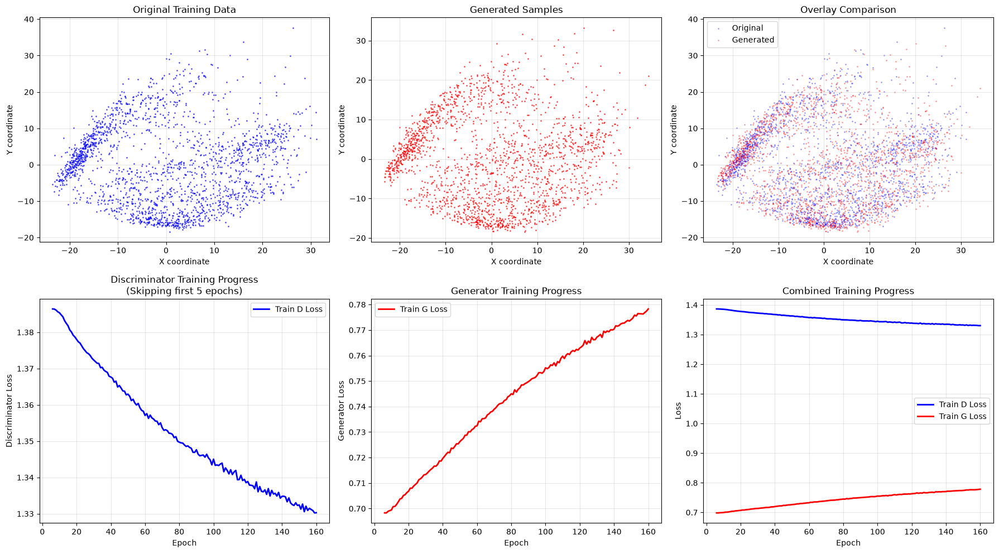

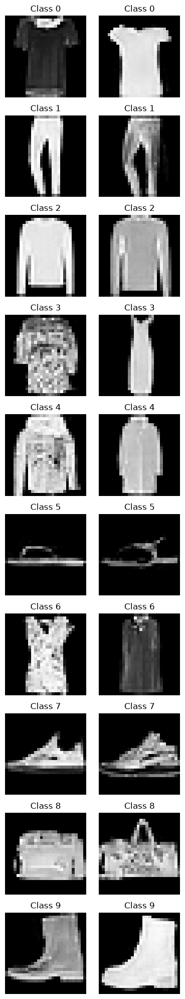

📈 Epoch 160 Summary:
   Train D Loss: 1.3303, Val D Loss: 1.4797
   Train G Loss: 0.7783, Val G Loss: 0.4845

📊 Epoch 161/200
----------------------------------------
Epoch: 161 [0/60000 (0%)]	D_loss: 1.307213	G_loss: 0.780709
Epoch: 161 [6400/60000 (11%)]	D_loss: 1.311047	G_loss: 0.783145
Epoch: 161 [12800/60000 (21%)]	D_loss: 1.364391	G_loss: 0.769006
Epoch: 161 [19200/60000 (32%)]	D_loss: 1.342006	G_loss: 0.762679
Epoch: 161 [25600/60000 (43%)]	D_loss: 1.352775	G_loss: 0.790679
Epoch: 161 [32000/60000 (53%)]	D_loss: 1.315181	G_loss: 0.782092
Epoch: 161 [38400/60000 (64%)]	D_loss: 1.286413	G_loss: 0.796057
Epoch: 161 [44800/60000 (75%)]	D_loss: 1.369336	G_loss: 0.819423
Epoch: 161 [51200/60000 (85%)]	D_loss: 1.346187	G_loss: 0.789008
Epoch: 161 [57600/60000 (96%)]	D_loss: 1.313096	G_loss: 0.793805
====> Epoch: 161 Train D_loss: 1.3291, Train G_loss: 0.7787
====> Epoch: 161 Val D_loss: 1.3864, Val G_loss: 0.6678
📈 Epoch 161 Summary:
   Train D Loss: 1.3291, Val D Loss: 1.3864
   Train

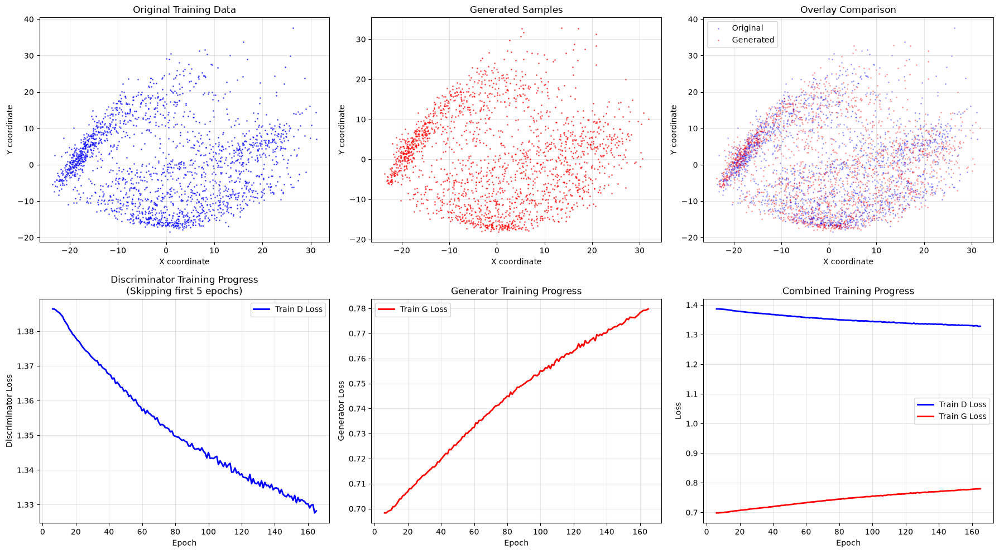

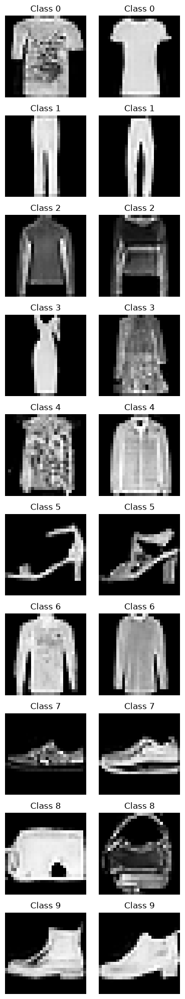

📈 Epoch 165 Summary:
   Train D Loss: 1.3282, Val D Loss: 1.3957
   Train G Loss: 0.7798, Val G Loss: 0.6515

📊 Epoch 166/200
----------------------------------------
Epoch: 166 [0/60000 (0%)]	D_loss: 1.329801	G_loss: 0.794070
Epoch: 166 [6400/60000 (11%)]	D_loss: 1.320016	G_loss: 0.764157
Epoch: 166 [12800/60000 (21%)]	D_loss: 1.326918	G_loss: 0.766509
Epoch: 166 [19200/60000 (32%)]	D_loss: 1.326911	G_loss: 0.784966
Epoch: 166 [25600/60000 (43%)]	D_loss: 1.338378	G_loss: 0.760076
Epoch: 166 [32000/60000 (53%)]	D_loss: 1.314068	G_loss: 0.743270
Epoch: 166 [38400/60000 (64%)]	D_loss: 1.331570	G_loss: 0.755000
Epoch: 166 [44800/60000 (75%)]	D_loss: 1.327934	G_loss: 0.753202
Epoch: 166 [51200/60000 (85%)]	D_loss: 1.341658	G_loss: 0.785800
Epoch: 166 [57600/60000 (96%)]	D_loss: 1.326600	G_loss: 0.760574
====> Epoch: 166 Train D_loss: 1.3282, Train G_loss: 0.7796
====> Epoch: 166 Val D_loss: 1.4348, Val G_loss: 0.9606
📈 Epoch 166 Summary:
   Train D Loss: 1.3282, Val D Loss: 1.4348
   Train

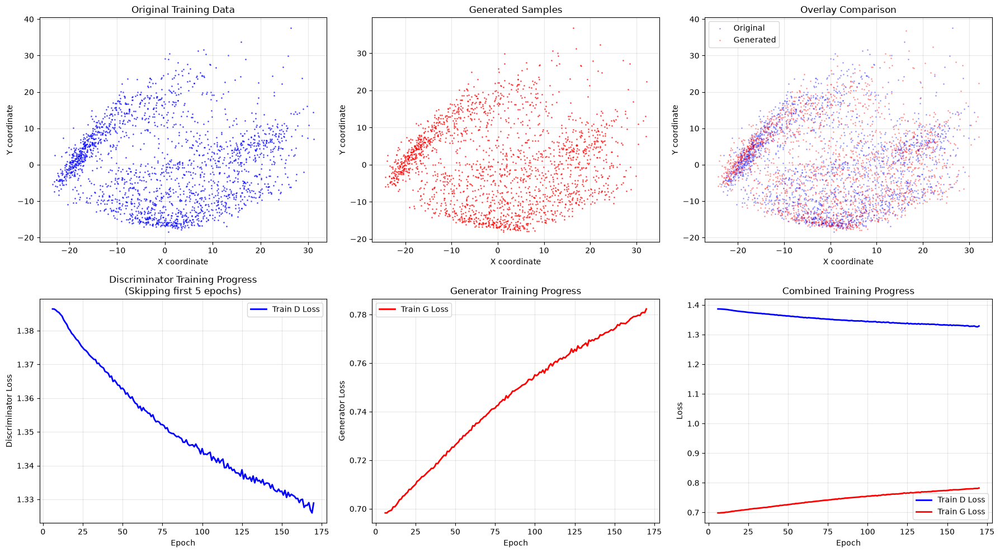

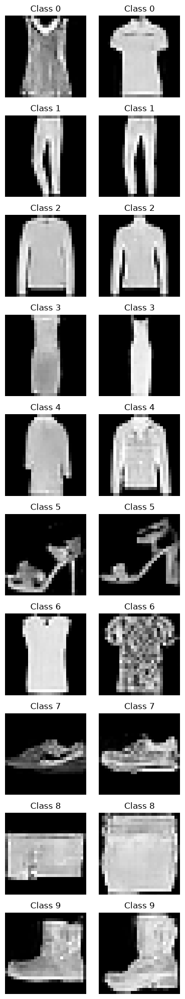

📈 Epoch 170 Summary:
   Train D Loss: 1.3289, Val D Loss: 1.4185
   Train G Loss: 0.7823, Val G Loss: 0.6092

📊 Epoch 171/200
----------------------------------------
Epoch: 171 [0/60000 (0%)]	D_loss: 1.330026	G_loss: 0.734594
Epoch: 171 [6400/60000 (11%)]	D_loss: 1.352636	G_loss: 0.779553
Epoch: 171 [12800/60000 (21%)]	D_loss: 1.305265	G_loss: 0.811803
Epoch: 171 [19200/60000 (32%)]	D_loss: 1.310148	G_loss: 0.767894
Epoch: 171 [25600/60000 (43%)]	D_loss: 1.330224	G_loss: 0.796724
Epoch: 171 [32000/60000 (53%)]	D_loss: 1.327585	G_loss: 0.803999
Epoch: 171 [38400/60000 (64%)]	D_loss: 1.310960	G_loss: 0.839372
Epoch: 171 [44800/60000 (75%)]	D_loss: 1.303707	G_loss: 0.760122
Epoch: 171 [51200/60000 (85%)]	D_loss: 1.400582	G_loss: 0.778482
Epoch: 171 [57600/60000 (96%)]	D_loss: 1.306417	G_loss: 0.774203
====> Epoch: 171 Train D_loss: 1.3285, Train G_loss: 0.7828
====> Epoch: 171 Val D_loss: 1.4187, Val G_loss: 0.8488
📈 Epoch 171 Summary:
   Train D Loss: 1.3285, Val D Loss: 1.4187
   Train

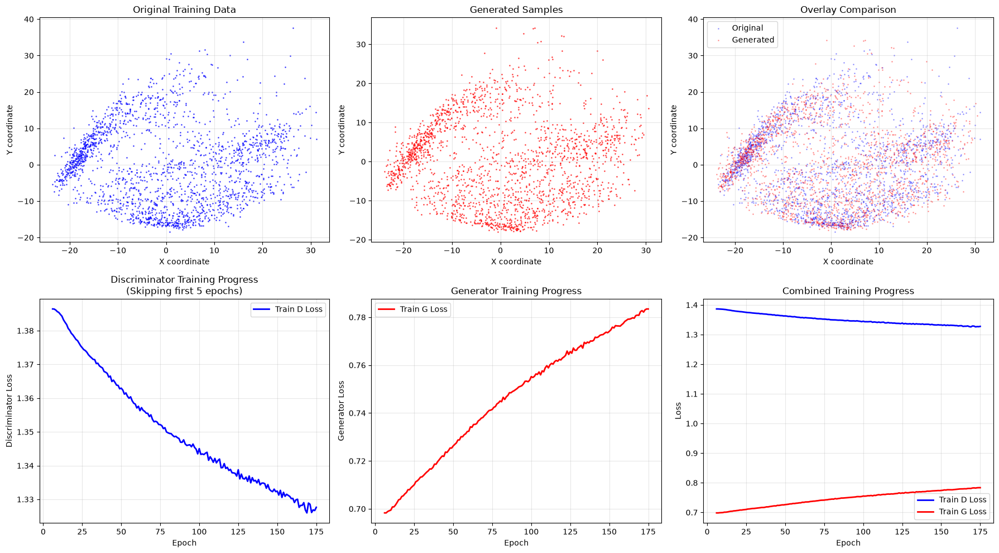

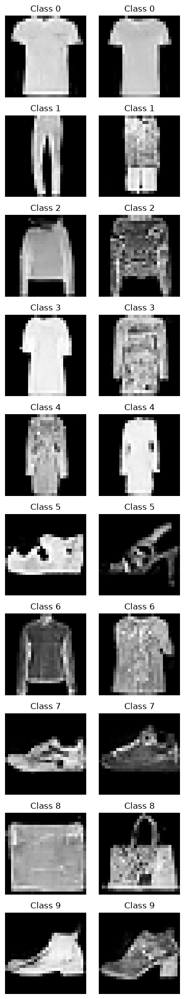

📈 Epoch 175 Summary:
   Train D Loss: 1.3276, Val D Loss: 1.4151
   Train G Loss: 0.7834, Val G Loss: 0.6047

📊 Epoch 176/200
----------------------------------------
Epoch: 176 [0/60000 (0%)]	D_loss: 1.304958	G_loss: 0.855549
Epoch: 176 [6400/60000 (11%)]	D_loss: 1.327121	G_loss: 0.779744
Epoch: 176 [12800/60000 (21%)]	D_loss: 1.307266	G_loss: 0.786483
Epoch: 176 [19200/60000 (32%)]	D_loss: 1.299995	G_loss: 0.781020
Epoch: 176 [25600/60000 (43%)]	D_loss: 1.322428	G_loss: 0.772542
Epoch: 176 [32000/60000 (53%)]	D_loss: 1.350083	G_loss: 0.799500
Epoch: 176 [38400/60000 (64%)]	D_loss: 1.327840	G_loss: 0.765570
Epoch: 176 [44800/60000 (75%)]	D_loss: 1.316728	G_loss: 0.751090
Epoch: 176 [51200/60000 (85%)]	D_loss: 1.272948	G_loss: 0.793308
Epoch: 176 [57600/60000 (96%)]	D_loss: 1.311721	G_loss: 0.776971
====> Epoch: 176 Train D_loss: 1.3258, Train G_loss: 0.7835
====> Epoch: 176 Val D_loss: 1.3945, Val G_loss: 0.8424
📈 Epoch 176 Summary:
   Train D Loss: 1.3258, Val D Loss: 1.3945
   Train

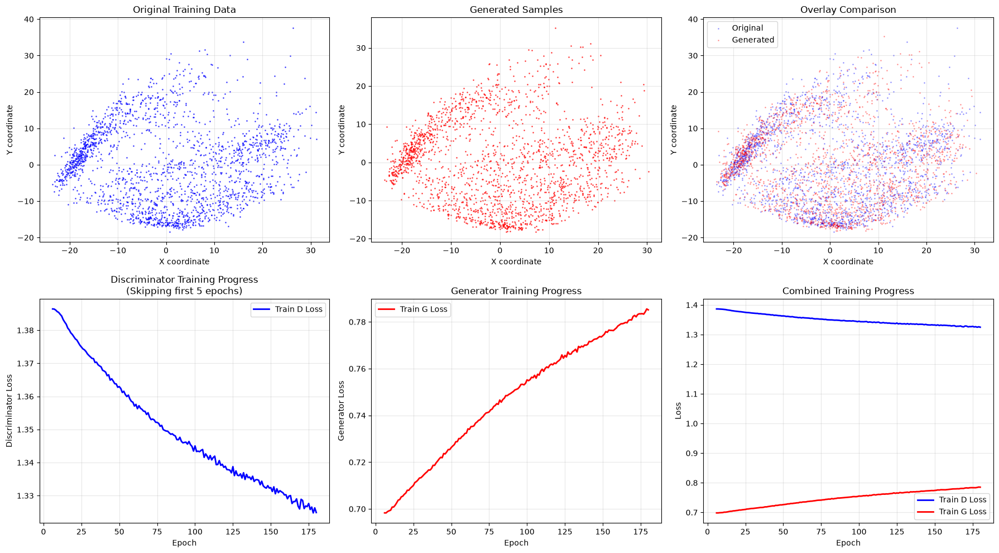

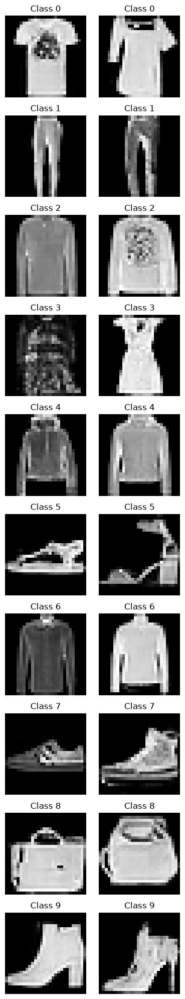

📈 Epoch 180 Summary:
   Train D Loss: 1.3249, Val D Loss: 1.3937
   Train G Loss: 0.7852, Val G Loss: 0.8155

📊 Epoch 181/200
----------------------------------------
Epoch: 181 [0/60000 (0%)]	D_loss: 1.320323	G_loss: 0.792310
Epoch: 181 [6400/60000 (11%)]	D_loss: 1.298470	G_loss: 0.852067
Epoch: 181 [12800/60000 (21%)]	D_loss: 1.320894	G_loss: 0.771059
Epoch: 181 [19200/60000 (32%)]	D_loss: 1.311622	G_loss: 0.774452
Epoch: 181 [25600/60000 (43%)]	D_loss: 1.341825	G_loss: 0.780661
Epoch: 181 [32000/60000 (53%)]	D_loss: 1.303779	G_loss: 0.794948
Epoch: 181 [38400/60000 (64%)]	D_loss: 1.342553	G_loss: 0.823090
Epoch: 181 [44800/60000 (75%)]	D_loss: 1.297422	G_loss: 0.799377
Epoch: 181 [51200/60000 (85%)]	D_loss: 1.297289	G_loss: 0.826012
Epoch: 181 [57600/60000 (96%)]	D_loss: 1.338068	G_loss: 0.810471
====> Epoch: 181 Train D_loss: 1.3253, Train G_loss: 0.7861
====> Epoch: 181 Val D_loss: 1.4172, Val G_loss: 0.8143
📈 Epoch 181 Summary:
   Train D Loss: 1.3253, Val D Loss: 1.4172
   Train

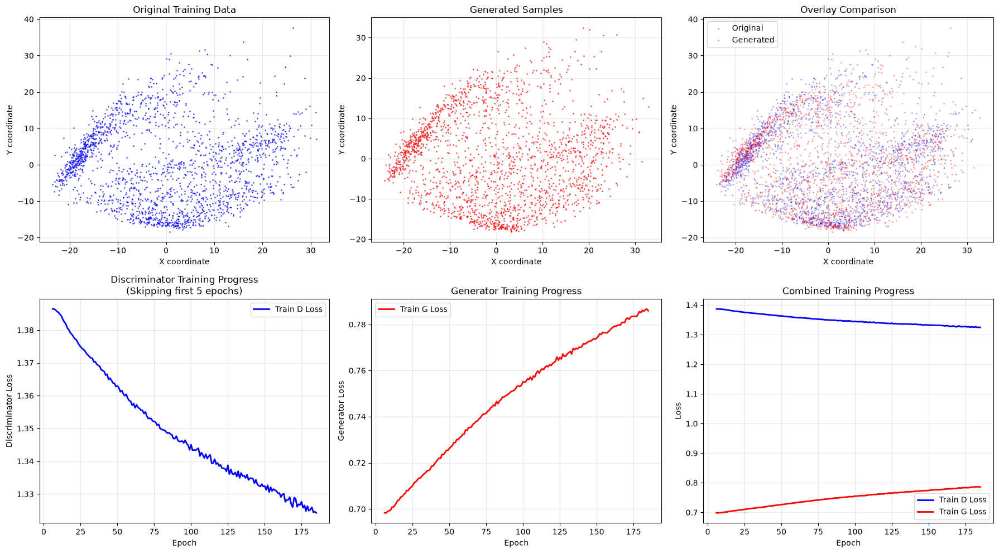

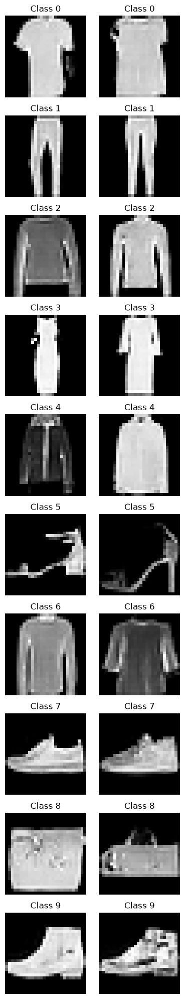

📈 Epoch 185 Summary:
   Train D Loss: 1.3242, Val D Loss: 1.4917
   Train G Loss: 0.7859, Val G Loss: 0.5385

📊 Epoch 186/200
----------------------------------------
Epoch: 186 [0/60000 (0%)]	D_loss: 1.347519	G_loss: 0.816760
Epoch: 186 [6400/60000 (11%)]	D_loss: 1.304793	G_loss: 0.829257
Epoch: 186 [12800/60000 (21%)]	D_loss: 1.357551	G_loss: 0.795843
Epoch: 186 [19200/60000 (32%)]	D_loss: 1.320656	G_loss: 0.771142
Epoch: 186 [25600/60000 (43%)]	D_loss: 1.341837	G_loss: 0.789271
Epoch: 186 [32000/60000 (53%)]	D_loss: 1.334390	G_loss: 0.780610
Epoch: 186 [38400/60000 (64%)]	D_loss: 1.311237	G_loss: 0.783331
Epoch: 186 [44800/60000 (75%)]	D_loss: 1.307061	G_loss: 0.765195
Epoch: 186 [51200/60000 (85%)]	D_loss: 1.298246	G_loss: 0.808348
Epoch: 186 [57600/60000 (96%)]	D_loss: 1.333205	G_loss: 0.770159
====> Epoch: 186 Train D_loss: 1.3229, Train G_loss: 0.7862
====> Epoch: 186 Val D_loss: 1.4628, Val G_loss: 1.0538
📈 Epoch 186 Summary:
   Train D Loss: 1.3229, Val D Loss: 1.4628
   Train

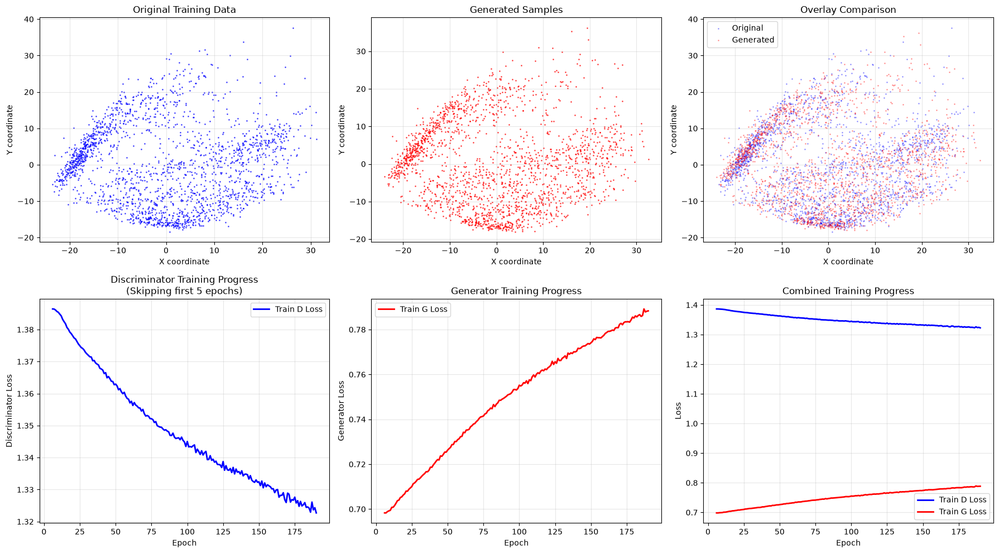

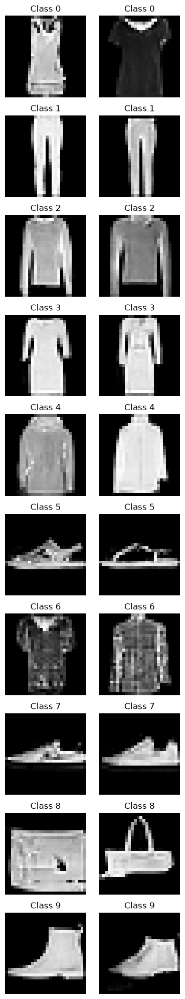

📈 Epoch 190 Summary:
   Train D Loss: 1.3227, Val D Loss: 1.3853
   Train G Loss: 0.7883, Val G Loss: 0.7753

📊 Epoch 191/200
----------------------------------------
Epoch: 191 [0/60000 (0%)]	D_loss: 1.295165	G_loss: 0.791860
Epoch: 191 [6400/60000 (11%)]	D_loss: 1.335995	G_loss: 0.793600
Epoch: 191 [12800/60000 (21%)]	D_loss: 1.316669	G_loss: 0.761191
Epoch: 191 [19200/60000 (32%)]	D_loss: 1.294466	G_loss: 0.793554
Epoch: 191 [25600/60000 (43%)]	D_loss: 1.318298	G_loss: 0.820871
Epoch: 191 [32000/60000 (53%)]	D_loss: 1.306710	G_loss: 0.768288
Epoch: 191 [38400/60000 (64%)]	D_loss: 1.301737	G_loss: 0.814554
Epoch: 191 [44800/60000 (75%)]	D_loss: 1.332398	G_loss: 0.757700
Epoch: 191 [51200/60000 (85%)]	D_loss: 1.313945	G_loss: 0.782522
Epoch: 191 [57600/60000 (96%)]	D_loss: 1.322563	G_loss: 0.770740
====> Epoch: 191 Train D_loss: 1.3236, Train G_loss: 0.7898
====> Epoch: 191 Val D_loss: 1.5526, Val G_loss: 1.2204
📈 Epoch 191 Summary:
   Train D Loss: 1.3236, Val D Loss: 1.5526
   Train

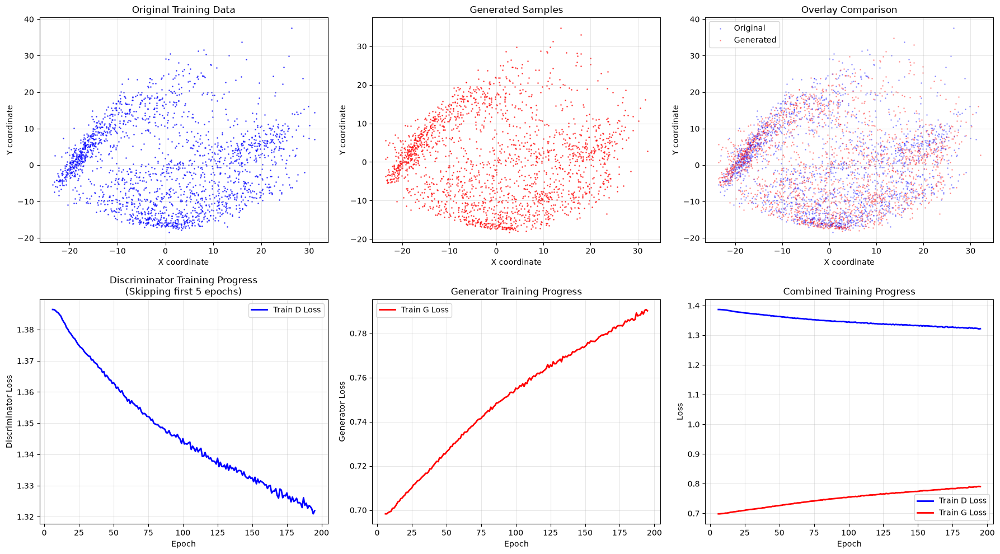

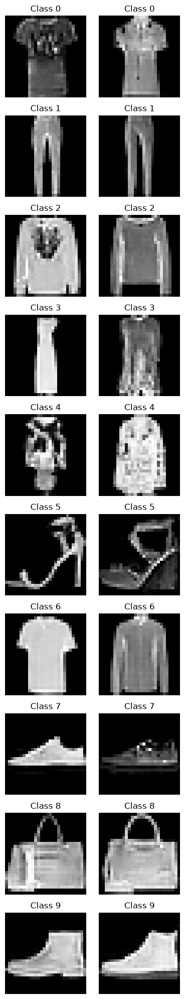

📈 Epoch 195 Summary:
   Train D Loss: 1.3219, Val D Loss: 1.4880
   Train G Loss: 0.7902, Val G Loss: 0.5444

📊 Epoch 196/200
----------------------------------------
Epoch: 196 [0/60000 (0%)]	D_loss: 1.317260	G_loss: 0.834508
Epoch: 196 [6400/60000 (11%)]	D_loss: 1.325295	G_loss: 0.784786
Epoch: 196 [12800/60000 (21%)]	D_loss: 1.305625	G_loss: 0.780739
Epoch: 196 [19200/60000 (32%)]	D_loss: 1.327503	G_loss: 0.799620
Epoch: 196 [25600/60000 (43%)]	D_loss: 1.327162	G_loss: 0.746604
Epoch: 196 [32000/60000 (53%)]	D_loss: 1.345090	G_loss: 0.758487
Epoch: 196 [38400/60000 (64%)]	D_loss: 1.285940	G_loss: 0.777159
Epoch: 196 [44800/60000 (75%)]	D_loss: 1.356980	G_loss: 0.763019
Epoch: 196 [51200/60000 (85%)]	D_loss: 1.307128	G_loss: 0.766710
Epoch: 196 [57600/60000 (96%)]	D_loss: 1.294007	G_loss: 0.788589
====> Epoch: 196 Train D_loss: 1.3233, Train G_loss: 0.7919
====> Epoch: 196 Val D_loss: 1.5022, Val G_loss: 0.5076
📈 Epoch 196 Summary:
   Train D Loss: 1.3233, Val D Loss: 1.5022
   Train

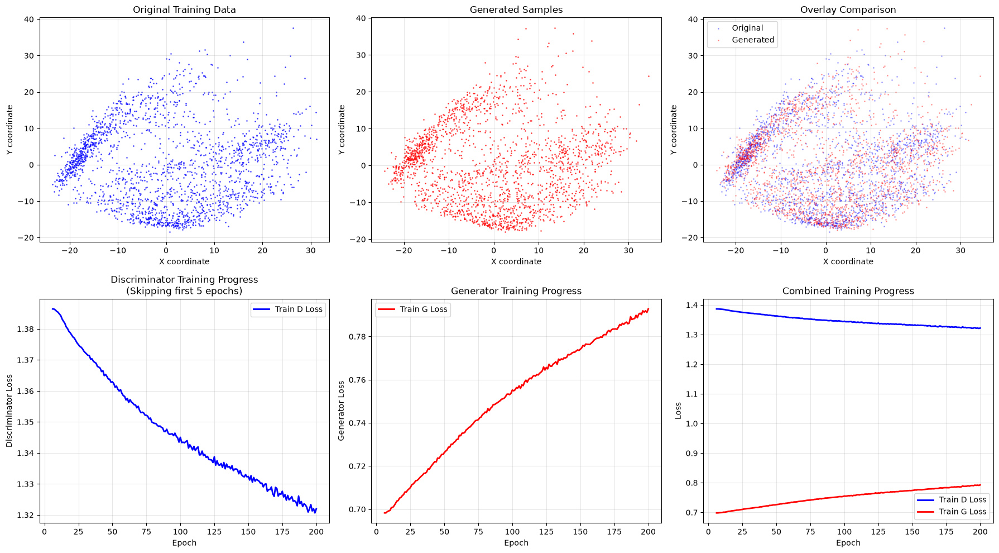

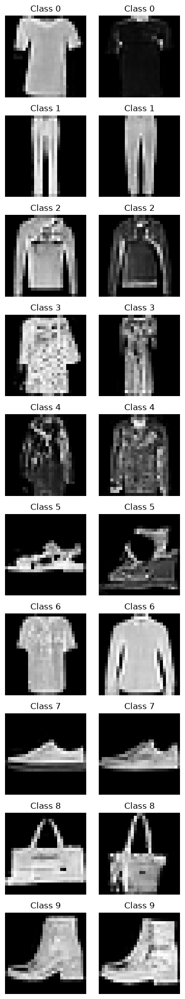

📈 Epoch 200 Summary:
   Train D Loss: 1.3220, Val D Loss: 1.3938
   Train G Loss: 0.7928, Val G Loss: 0.7964

🎉 Training completed!

🎨 Final comprehensive visualization:


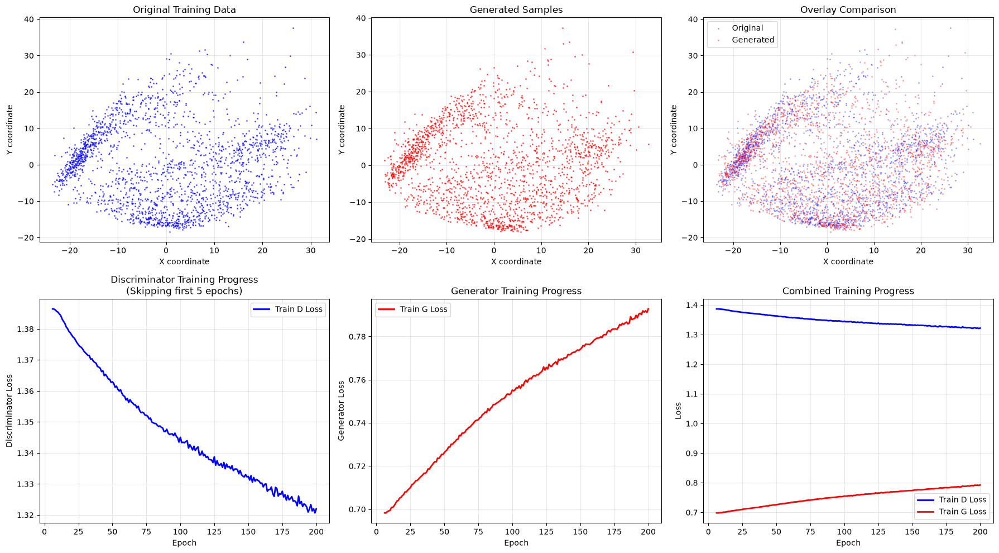

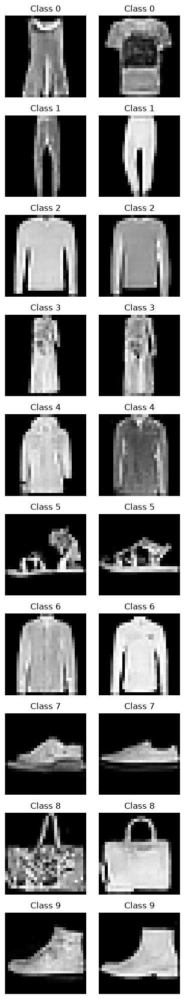

In [14]:
# Training loop
print("🎯 Starting GAN training...")
print("=" * 60)

# Lists to track training progress
train_d_losses = []
train_g_losses = []
val_d_losses = []
val_g_losses = []

# Show initial state (before training)
print("📊 Initial state (before training):")

for epoch in range(1, EPOCHS + 1):
    print(f"\n📊 Epoch {epoch}/{EPOCHS}")
    print("-" * 40)
    
    # Train for one epoch with validation
    train_d_loss, train_g_loss, val_d_loss, val_g_loss = train_epoch_with_validation(epoch)
    
    # Track losses
    train_d_losses.append(train_d_loss)
    train_g_losses.append(train_g_loss)
    val_d_losses.append(val_d_loss)
    val_g_losses.append(val_g_loss)
    
    # Visualize progress every 5 epochs
    if epoch % SAVE_PLT_INTERVAL == 0:
        print(f"\n🎨 Visualizing progress at epoch {epoch}...")
        visualize_training_progress(epoch, train_d_losses, train_g_losses, val_d_losses, val_g_losses)
    
    print(f"📈 Epoch {epoch} Summary:")
    print(f"   Train D Loss: {train_d_loss:.4f}, Val D Loss: {val_d_loss:.4f}")
    print(f"   Train G Loss: {train_g_loss:.4f}, Val G Loss: {val_g_loss:.4f}")

print("\n🎉 Training completed!")
print("=" * 60)

# Save the trained models
# torch.save(generator.state_dict(), 'generator.pth')
# torch.save(discriminator.state_dict(), 'discriminator.pth')
# print("💾 Models saved as 'generator.pth' and 'discriminator.pth'")

# Final comprehensive visualization
print("\n🎨 Final comprehensive visualization:")
visualize_training_progress(EPOCHS, train_d_losses, train_g_losses, val_d_losses, val_g_losses)


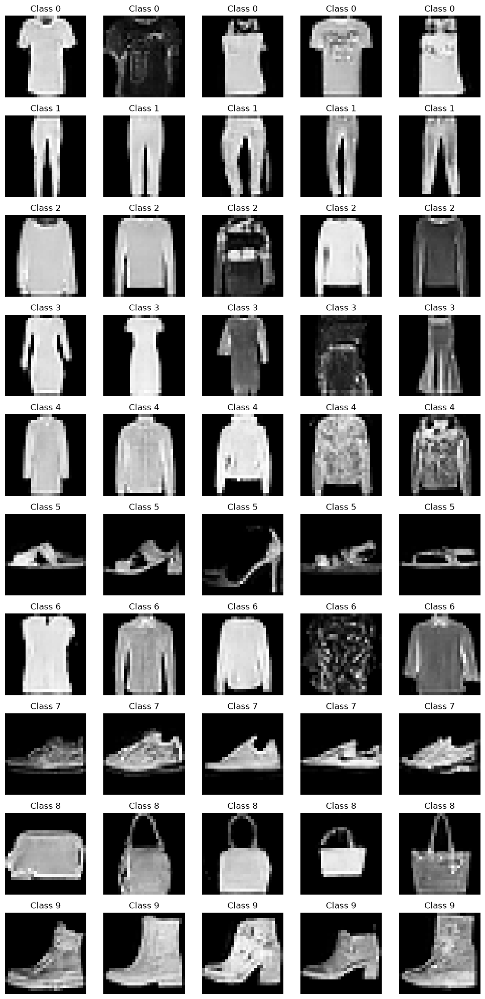

Real data confidence with matching classes: 0.510
Fake data confidence with requested classes: 0.459


In [15]:
TARGET_CLASSES = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
SAMPLES_PER_CLASS = 5

visualize_class_samples(TARGET_CLASSES, samples_per_class=SAMPLES_PER_CLASS)

generated_sevens = generate_samples(20, classes=7)
generated_digits = generate_samples(len(TARGET_CLASSES), classes=TARGET_CLASSES)

generator.eval()
discriminator.eval()
with torch.no_grad():
    real_batch = train_data.data[:100].unsqueeze(1).to(device).float() / 255.0
    real_classes = train_data.targets[:100].to(device)
    real_pred = discriminator(real_batch, real_classes).mean().item()

    fake_classes = torch.tensor(TARGET_CLASSES, device=device).repeat(100)[:100]
    noise = torch.randn(100, NOISE_DIM, device=device)
    fake_batch = generator(noise, fake_classes)
    fake_pred = discriminator(fake_batch, fake_classes).mean().item()

print(f'Real data confidence with matching classes: {real_pred:.3f}')
print(f'Fake data confidence with requested classes: {fake_pred:.3f}')
